<a href="https://colab.research.google.com/github/zuvelatamara/PPPO-2025/blob/main/PPPO_V6_Case_study_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# POČETAK PRVOG ČASA

# **Case study 2: Klasifikacija rendgenskih snimaka grudnog koša (COVID-19)**

Ovaj case study radimo u **dva termina**:

| Čas | Sadržaj |
|---|---|
| **1. čas** | Dataset, analiza podataka (EDA), metode povećanja kontrasta, augmentacija, metodologija prvog rada (EfficientNetB1, NasNetMobile, MobileNetV2) |
| **2. čas** | CovXNet (drugi rad), DeTraC (treći rad) sa praktičnom implementacijom, kritički osvrt na rezultate |


Related papers:
* Chest X-ray Classification for the Detection of COVID-19 Using Deep Learning Techniques
* Mahmud, T.; Rahman, M.A.; Fattah, S.A. CovXNet: A multi-dilation convolutional neural network for automatic COVID-19 and
other pneumonia detection from chest X-ray images with transferable multi-receptive feature optimization. Comput. Biol. Med.
2020, 122, 103869
* Abbas, A.; Abdelsamea, M.M.; Gaber, M.M. Classification of COVID-19 in chest X-ray images using DeTraC deep convolutional
neural network. Appl. Intell. 2021, 51, 854–864

**Dataset**

The dataset used for training and evaluation of the proposed technique is publicly
available on Kaggle: [COVID-19 Radiography Database-Kaggle](https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database/data).


---


U ovom istraživanju korišćen je revidirani skup podataka sa platforme Kaggle, koji je sastavljen spajanjem više podskupova i obuhvata četiri klase:
* COVID-19,
* zamućenje pluća (lung opacity),
* normalne i
* virusne pneumonije.

Svaka klasa formirana je kombinovanjem različitih izvora medicinskih snimaka.

Klasa COVID-19 sadrži ukupno 3616 rendgenskih (CXR) snimaka, prikupljenih iz četiri glavna izvora. Najveći doprinos dolazi iz BIMCV-COVID19+ baze podataka sa 2473 snimka, koja predstavlja jedan od najopsežnijih javno dostupnih setova. Dodatno, uključeno je 183 snimka iz baze nemačke medicinske škole, 560 snimaka preuzetih sa platformi SIRM, GitHub, Kaggle i Twitter, kao i 400 snimaka sa drugog javnog GitHub izvora.

RSNA Pneumonia Challenge dataset, poznat po obuhvatu različitih plućnih anomalija i normalnih pluća, takođe je iskorišćen. Ovaj skup sadrži 26.684 snimka u DICOM formatu, raspoređenih u tri glavne kategorije:
– 6012 snimaka označenih kao zamućenje pluća (non-COVID infekcije),
– 8851 snimak zdravih pluća,
– kao i snimke različitih plućnih infekcija, uključujući rak pluća.

Snimke su pregledali medicinski stručnjaci, uz uvid u kliničku istoriju pacijenata, kako bi se izbegla pogrešna klasifikacija. Dataset je kasnije proširen dodatkom 1341 normalnog snimka i 1345 snimaka virusne pneumonije.

Ovaj objedinjeni dataset rezultat je saradnje istraživača sa Univerziteta u Kataru, Univerziteta u Daki, kao i stručnjaka iz Pakistana i Malezije, u saradnji sa medicinskim timovima. U okviru više faza objavljivanja, broj slika je postepeno povećavan — od početnih 219 COVID-19 snimaka do sadašnjih 3616 COVID-19, uz 10.192 normalna, 6012 snimaka zamućenja pluća i 1345 snimaka virusne pneumonije.
Ova baza se i dalje periodično ažurira dodavanjem novih podataka o pacijentima sa potvrđenom COVID-19 pneumonijom.


**Napomena:** u ovoj svesci sav kod radi na ovom Kaggle dataset-u. Od tri rada koja obrađujemo, samo je prvi rad koristio isti dataset. CovXNet i DeTraC su koristili svoje, manje skupove podataka, pa njihove rezultate ne možemo direktno porediti sa našim.

Važno je i to da snimci dolaze iz **različitih izvora** (bolnice, članci, internet). Na to ćemo se vratiti na kraju case study-ja.

#**Struktura dataset-a**

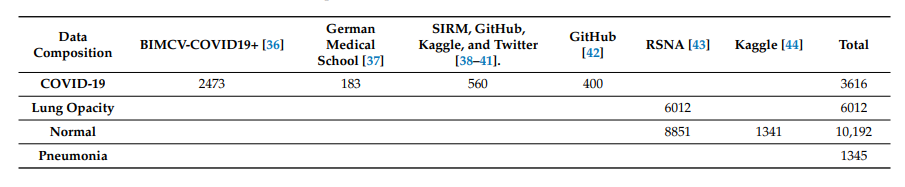

# **Analiza  dataset-a**

In [2]:
import os
import time
import random
import shutil
from glob import glob

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
from tqdm.auto import tqdm
import tensorflow as tf

**Preuzimanje dataset-a**

Dataset preuzimamo direktno sa Kaggle-a pomoću biblioteke `kagglehub`, bez ručnog upload-a zip fajla. Biblioteka ga preuzme i raspakuje, a mi napravimo prečicu na `/content/COVID-19_Radiography_Dataset`, da sve putanje u svesci ostanu iste.

In [3]:
# Preuzimanje dataset-a direktno sa Kaggle-a (za javne dataset-ove nije potrebna prijava)
import kagglehub
putanja = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")
print(putanja)

# Prečica, da bi sve putanje u svesci ostale /content/COVID-19_Radiography_Dataset
!ln -sfn "{putanja}/COVID-19_Radiography_Dataset" /content/COVID-19_Radiography_Dataset
!ls /content/COVID-19_Radiography_Dataset

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
/kaggle/input/covid19-radiography-database
 COVID			      Normal.metadata.xlsx
 COVID.metadata.xlsx	      README.md.txt
 Lung_Opacity		     'Viral Pneumonia'
 Lung_Opacity.metadata.xlsx  'Viral Pneumonia.metadata.xlsx'
 Normal


In [4]:
data_dir = '/content/COVID-19_Radiography_Dataset'
covid_image_dir = '/content/COVID-19_Radiography_Dataset/COVID/images'
non_covid_image_dir = '/content/COVID-19_Radiography_Dataset/Normal/images'
viral_pheumonia_image_dir = '/content/COVID-19_Radiography_Dataset/Viral Pneumonia/images'

print(f'Number of COVID Images: {len(os.listdir(covid_image_dir))} \nNumber of Non-COVID Images: {len(os.listdir(non_covid_image_dir))}\nNumber of Viral Pheumonia Images: {len(os.listdir(viral_pheumonia_image_dir))}')

Number of COVID Images: 3616 
Number of Non-COVID Images: 10192
Number of Viral Pheumonia Images: 1345


In [5]:
def resize(array, size, keep_ratio=False, resample=Image.LANCZOS):
    # Original from: https://www.kaggle.com/xhlulu/vinbigdata-process-and-resize-to-image
    im = Image.fromarray(array)

    if keep_ratio:
        im.thumbnail((size, size), resample)
    else:
        im = im.resize((size, size), resample)

    return np.array(im).reshape(size,size,3)

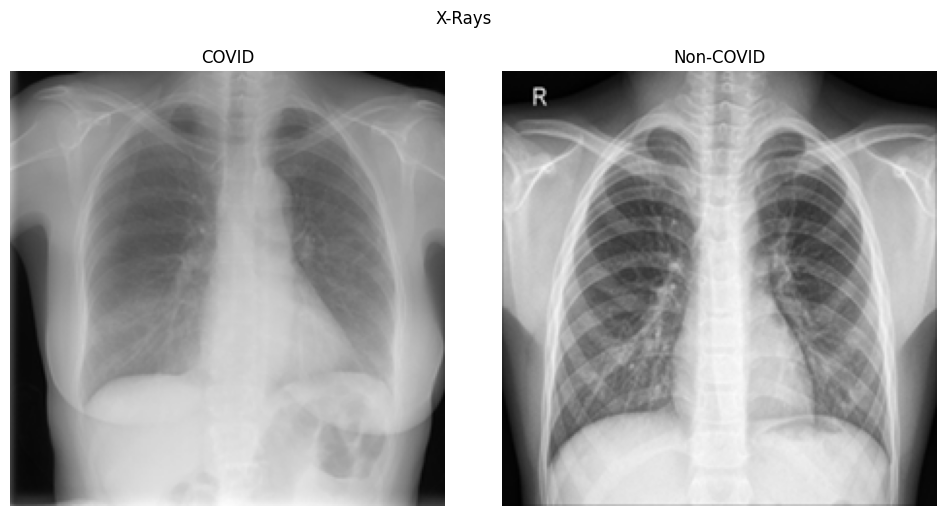

In [6]:
covid_example = resize(cv2.imread(os.path.join(covid_image_dir,os.listdir(covid_image_dir)[0])),224)
non_covid_example = resize(cv2.imread(os.path.join(non_covid_image_dir,os.listdir(non_covid_image_dir)[0])),224)

fig, axs = plt.subplots(nrows=1,ncols=2,figsize=[10,6])
fig.tight_layout()
axs[0].imshow(covid_example)
axs[0].set_title('COVID')
axs[0].axis('off')
axs[1].imshow(non_covid_example)
axs[1].set_title('Non-COVID')
axs[1].axis('off')
fig.suptitle('X-Rays')
plt.show()

# **Metode povećanja kontrasta**

Rendgenski snimci su često slabog kontrasta: većina piksela je u uskom opsegu sivih nijansi, pa se detalji u plućima slabo vide. Zato je povećanje kontrasta jedan od standardnih koraka predobrade medicinskih slika.

| Metoda | Kada koristiti | Napomena |
|---|---|---|
| **Histogram** | Za analizu slike | Osnovni alat, ne menja sliku. Pokazuje koliko piksela ima koju osvetljenost |
| **CDF** (kumulativna funkcija raspodele) | U procesu izjednačavanja kontrasta | Deo algoritma: sabira histogram od tamnih ka svetlim vrednostima |
| **Global Histogram Equalization** | Slika ujednačeno osvetljena, kontrast nizak | Razvlači vrednosti preko celog opsega 0–255; može pojačati šum |
| **AHE** (adaptivno izjednačavanje) | Neujednačeno osvetljenje | Radi lokalno, po delovima slike; može jako pojačati šum |
| **CLAHE** | Neujednačeno osvetljenje, potrebni detalji | AHE sa ograničenjem pojačanja; najčešće se koristi za medicinske slike |
| **S-curve** (sigmoid) | Blago, kontrolisano povećanje kontrasta | Zadržava prirodan izgled |
| **BEASF** | Kada želiš kombinaciju kontrasta i prirodnosti | Napredna metoda: deli histogram na dva dela (sub-histograme) i na svaki primenjuje S-krivu |

U ćelijama ispod implementiramo globalno izjednačavanje, S-krivu, BEASF (sa pomoćnim funkcijama `subhist` i `CDF`) i CLAHE, pa ih upoređujemo na istom COVID snimku.

In [7]:
import copy
import warnings

def histogram_equalization(image_data):
    """Globalno izjednačavanje histograma."""
    if type(image_data) is not np.ndarray:
        warnings.warn('Should be a numpy array')
    shape = image_data.shape

    # 1. histogram: koliko piksela ima koju vrednost (256 korpica)
    _histogram, _bins = np.histogram(image_data.flatten(), 256, density=True)

    # 2. CDF: kumulativni zbir histograma, normalizovan na opseg 0–255
    cdf = _histogram.cumsum()
    cdf = 255 * cdf / cdf[-1]

    # 3. svaki piksel dobija novu vrednost očitanu sa CDF krive
    image_data = np.interp(image_data.flatten(), _bins[:-1], cdf)
    return image_data.reshape(shape)

In [8]:
def histogram_s_curve(image_data):
    """Izjednačavanje histograma + S-kriva (sigmoid)."""
    # 1. prvo globalno izjednačavanje histograma
    image_data = histogram_equalization(image_data)
    shape = image_data.shape

    # 2. granice 256 korpica sivih nijansi (sam histogram nam ne treba)
    _, _bins = np.histogram(image_data.flatten(), 256, density=True)

    # 3. S-kriva (sigmoid): centar na 158, nagib 1/25
    #    vrednosti ispod 158 postaju tamnije, iznad 158 svetlije
    s_kriva = 1 / (1 + np.exp((1 / 25) * (158 - _bins)))
    s_kriva = 255 * s_kriva / s_kriva[-1]

    # 4. svaki piksel preslikavamo preko S-krive
    image_data = np.interp(image_data.flatten(), _bins, s_kriva)
    return image_data.reshape(shape)

In [9]:
def subhist(image_pdf, minimum, maximum, normalize):
    """Izdvaja deo histograma između vrednosti minimum i maximum.
    Ostale vrednosti ostaju 0. Ako je normalize=True, deo se normalizuje
    tako da mu zbir bude 1 (postaje samostalna raspodela)."""
    hi = np.zeros(shape=image_pdf.shape)
    total = 0
    for idx in range(minimum, maximum + 1):
        total += image_pdf[idx]
        hi[idx] = image_pdf[idx]
    if normalize:
        for idx in range(minimum, maximum + 1):
            hi[idx] /= total
    return hi

In [10]:
def CDF(hist):
    """Kumulativna funkcija raspodele: cdf[i] = hist[0] + hist[1] + ... + hist[i].
    Govori koliki udeo piksela ima vrednost manju ili jednaku i."""
    cdf = np.zeros(shape=hist.shape)
    cdf[0] = hist[0]
    for idx in range(1, len(hist)):
        cdf[idx] = cdf[idx - 1] + hist[idx]
    return cdf

In [11]:
def BEASF(image, gamma=1.5):
    """BEASF: Bi-histogram Equalization using Adaptive Sigmoid Functions.
    Histogram se deli na tamni i svetli deo, i na svaki se primenjuje posebna S-kriva."""
    image = np.array(image)

    # KORAK 1: srednja osvetljenost m deli histogram na dva dela
    m = int(np.mean(image, dtype=np.int32))
    h = np.histogram(image, bins=256)[0] / (image.shape[0] * image.shape[1])
    h_lower = subhist(image_pdf=h, minimum=0, maximum=m, normalize=True)    # tamni deo
    h_upper = subhist(image_pdf=h, minimum=m, maximum=255, normalize=True)  # svetli deo

    # KORAK 2: CDF svakog dela i njegova "sredina" (medijana), gde CDF pređe 0.5
    cdf_lower = CDF(hist=h_lower)
    cdf_upper = CDF(hist=h_upper)

    half_low = 0
    for idx in range(0, m + 2):
        if cdf_lower[idx] > 0.5:
            half_low = idx
            break
    half_up = 0
    for idx in range(m, 256):
        if cdf_upper[idx + 1] > 0.5:
            half_up = idx
            break

    # KORAK 3: dve S-krive (sigmoide), centrirane na medijanama oba dela;
    # gamma određuje strminu krive, odnosno koliko se kontrast pojačava
    tones_low = np.arange(0, m + 1, 1)
    x_low = 5.0 * (tones_low - half_low) / m              # skaliranje na opseg oko [-2.5, 2.5]
    s_low = 1 / (1 + np.exp(-gamma * x_low))              # donja sigmoida
    tones_up = np.arange(m, 256, 1)
    x_up = 5.0 * (tones_up - half_up) / (255 - m)
    s_up = 1 / (1 + np.exp(-gamma * x_up))                # gornja sigmoida

    # KORAK 4: tabela preslikavanja (stara vrednost -> nova vrednost)
    # tamni deo se razvlači na opseg [0, m]
    mapping_vector = np.zeros(shape=(256,))
    for idx in range(0, m + 1):
        mapping_vector[idx] = np.int32(m * s_low[idx])
    minimum = mapping_vector[0]
    maximum = mapping_vector[m]
    for idx in range(0, m + 1):
        mapping_vector[idx] = np.int32((m / (maximum - minimum)) * (mapping_vector[idx] - minimum))

    # svetli deo se razvlači na opseg [m, 255]
    for idx in range(m + 1, 256):
        mapping_vector[idx] = np.int32(m + (255 - m) * s_up[idx - m - 1])
    minimum = mapping_vector[m + 1]
    maximum = mapping_vector[255]
    for idx in range(m + 1, 256):
        mapping_vector[idx] = (255 - m) * (mapping_vector[idx] - minimum) / (maximum - minimum) + m

    # KORAK 5: svaki piksel zamenjujemo vrednošću iz tabele
    res = copy.deepcopy(image)
    res[:, :] = mapping_vector[image[:, :]]
    return res

In [12]:
def CLAHE(img):
    """CLAHE: Contrast Limited Adaptive Histogram Equalization."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)        # CLAHE radi na jednom kanalu
    # clipLimit: koliko se kontrast sme pojačati (veće = jače, ali više šuma)
    # tileGridSize: slika se deli na 8x8 = 64 pločice, svaka se obrađuje posebno
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray = clahe.apply(gray)
    gray = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)       # nazad u 3 kanala, da prikaz bude isti kao kod ostalih
    return gray

In [13]:
# histogram_equalization vraća decimalne brojeve (float), za prikaz slike pretvaramo ih u cele brojeve 0–255 (uint8)
histogram_equalizer = lambda x: np.array(histogram_equalization(x), dtype='uint8')

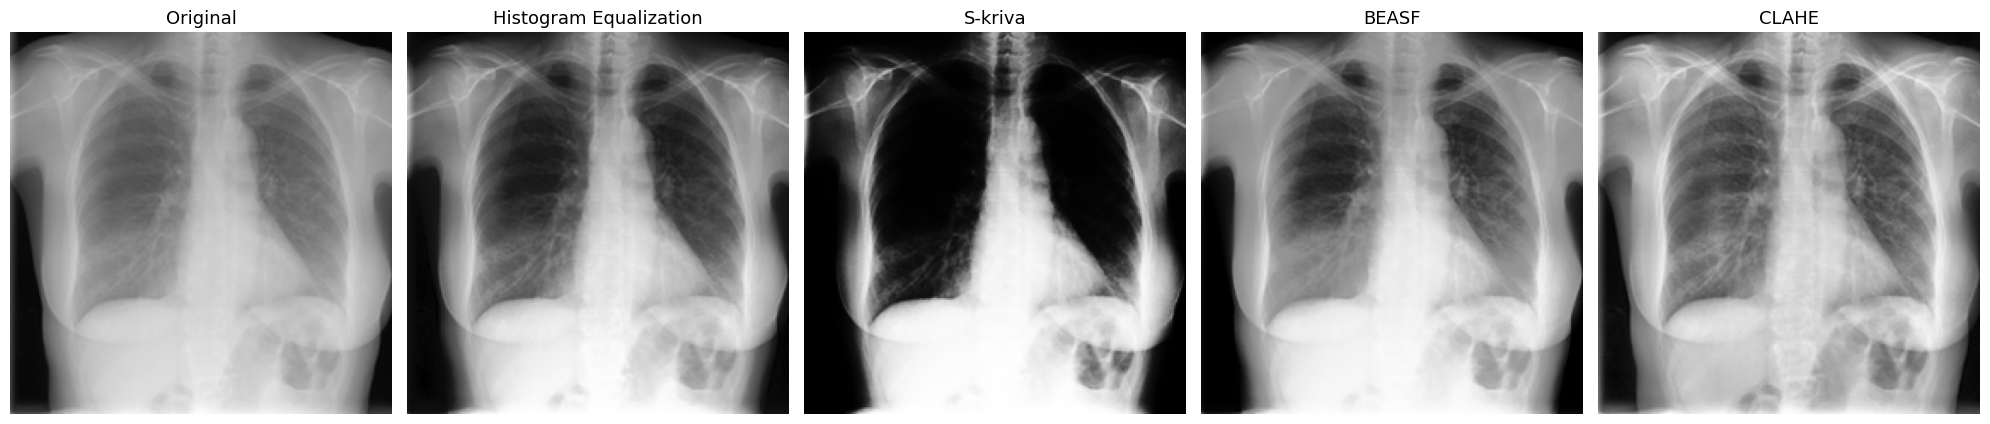

In [14]:
base_image = covid_example

rezultati = {
    'Original': base_image,
    'Histogram Equalization': histogram_equalizer(base_image),
    'S-kriva': np.array(histogram_s_curve(base_image), dtype='uint8'),
    'BEASF': BEASF(base_image),
    'CLAHE': CLAHE(base_image),
}

fig, axs = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, (naziv, slika) in zip(axs, rezultati.items()):
    ax.imshow(slika)
    ax.set_title(naziv, fontsize=13)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Poređenje metoda na COVID snimku:**

* **Original:** slika je „isprana”: većina piksela je u sredini sive skale, pluća su sivo-bela i detalji se slabo vide.
* **Histogram Equalization:** kontrast je znatno veći, pluća su tamnija, a rebra i krvni sudovi se bolje vide. Ali donji deo slike (stomak) i srce postaju skoro potpuno beli, pa se tu detalji gube.
* **S-kriva:** pojačanje je preterano. Pluća su skoro potpuno crna, a kosti i srce potpuno beli. Upravo u plućima, gde je bolest, izgubljen je najveći deo detalja. Ovde parametri (centar 158, nagib 1/25) nisu dobro izabrani za ovaj snimak.
* **BEASF:** rezultat je sličan globalnom izjednačavanju, ali umereniji i prirodniji, bez potpuno crnih i potpuno belih površina.
* **CLAHE:** najbolje ističe lokalne detalje: šara krvnih sudova u plućima, kičma kroz senku srca i detalji u stomaku ostaju vidljivi. Slika je malo zrnastija, jer lokalna obrada ističe i fine teksture.

**Zaključak:** za rendgenske snimke najviše odgovara **CLAHE**, jer pojačava detalje tamo gde nam trebaju (u plućima), a ne „pregori” ni tamne ni svetle delove. Zato se CLAHE najčešće koristi u radovima sa medicinskim slikama.

**Zašto S-kriva, koja je na drugim slikama dobra, ovde daje loš rezultat?**

Parametri krive su fiksni, a ne prilagođavaju se slici. Za ovaj snimak centar krive je previsoko, pa skoro sve sive nijanse pluća padnu u tamni deo.

In [15]:
# Glavni folder dataset-a (apsolutna putanja, radi bez obzira na trenutni folder)
path = "/content/COVID-19_Radiography_Dataset"

# Mapiranja klasa
diag_code_dict = {
    'COVID': 0,
    'Lung_Opacity': 1,
    'Normal': 2,
    'Viral Pneumonia': 3
}

diag_title_dict = {
    'COVID': 'Covid-19',
    'Lung_Opacity': 'Lung Opacity',
    'Normal': 'Healthy',
    'Viral Pneumonia': 'Viral Pneumonia'
}

# Struktura: <klasa>/images/*.png i <klasa>/masks/*.png
# Uzimamo SAMO folder images! Maske imaju ista imena fajlova kao snimci,
# pa bi pretraga svih podfoldera pomešala snimke i maske.
imageid_path_dict = {
    os.path.splitext(os.path.basename(x))[0]: x
    for x in glob(os.path.join(path, '*', 'images', '*.png'))
}
print(f"Broj pronađenih slika: {len(imageid_path_dict)}")   # očekujemo 21165

# Kreiranje DataFrame-a
covidData = pd.DataFrame.from_dict(imageid_path_dict, orient='index').reset_index()
covidData.columns = ['image_id', 'path']

# Klasa iz naziva slike, npr. "Viral Pneumonia-12" -> "Viral Pneumonia"
covidData['diag'] = covidData.image_id.str.split('-').str[0]
covidData['target'] = covidData['diag'].map(diag_code_dict)
covidData['Class'] = covidData['diag'].map(diag_title_dict)

covidData.head()

Broj pronađenih slika: 21165


,image_id,path,diag,target,Class
0,Normal-859,/content/COVID-19_Radiography_Dataset/Normal/i...,Normal,2,Healthy
1,Normal-158,/content/COVID-19_Radiography_Dataset/Normal/i...,Normal,2,Healthy
2,Normal-10121,/content/COVID-19_Radiography_Dataset/Normal/i...,Normal,2,Healthy
3,Normal-1811,/content/COVID-19_Radiography_Dataset/Normal/i...,Normal,2,Healthy
4,Normal-97,/content/COVID-19_Radiography_Dataset/Normal/i...,Normal,2,Healthy


**Važno:** svaka klasa ima dva podfoldera:
- `images` (rendgenski snimci) i
- `masks` (maske pluća, bele površine na crnoj pozadini).

Maske nisu snimci i ne smeju da uđu ni u analizu ni u treniranje. Zato u pretrazi navodimo baš folder `images` i proveravamo da je broj slika 21 165, kao u opisu dataset-a.

In [16]:
samples, features = covidData.shape
duplicated = covidData.duplicated().sum()        # isti redovi u tabeli (ne isti snimci!)
null_values = covidData.isnull().sum().sum()     # prazne vrednosti, npr. nepoznata klasa

print('Basic EDA')
print('Number of samples: %d' % samples)
print('Number of duplicated values: %d' % duplicated)
print('Number of Null samples: %d' % null_values)

Basic EDA
Number of samples: 21165
Number of duplicated values: 0
Number of Null samples: 0


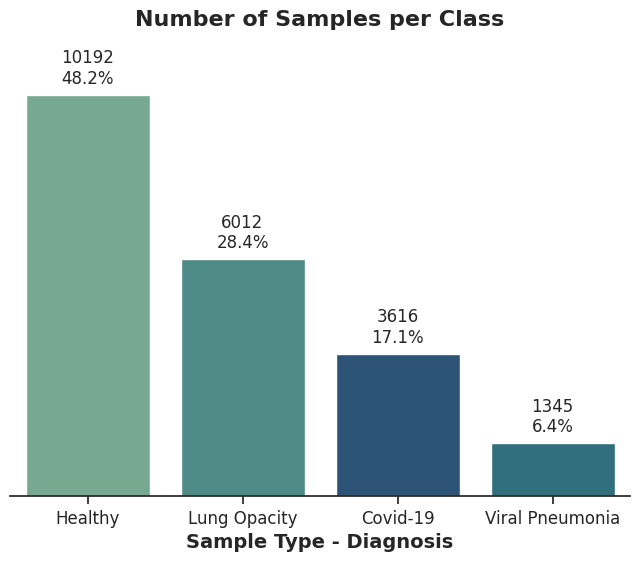

In [17]:
plt.figure(figsize=(8, 6))
sns.set(style="ticks", font_scale=1)
ax = sns.countplot(data=covidData, x='Class', hue='Class', legend=False,
                   order=covidData['Class'].value_counts().index, palette="crest")
sns.despine(top=True, right=True, left=True, bottom=False)
plt.xticks(rotation=0, fontsize=12)
ax.set_xlabel('Sample Type - Diagnosis', fontsize=14, weight='bold')
ax.axes.get_yaxis().set_visible(False)
plt.title('Number of Samples per Class', fontsize=16, weight='bold')

# Iznad svakog stubića: broj slika i procenat
for p in ax.patches:
    visina = p.get_height()
    if visina > 0:
        ax.annotate(f"{int(visina)}\n{100 * visina / samples:.1f}%",
                    (p.get_x() + p.get_width() / 2, visina),
                    ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
        ax.set_ylim(0, covidData['Class'].value_counts().max() * 1.15)   # malo prostora iznad stubića

plt.show()

**Neravnoteža klasa**

Klase u dataset-u nisu ravnomerno zastupljene:

| Klasa | Broj slika | Udeo |
|---|---|---|
| Healthy (zdrava pluća) | 10 192 | 48.2% |
| Lung Opacity (zamućenje pluća) | 6 012 | 28.4% |
| Covid-19 | 3 616 | 17.1% |
| Viral Pneumonia (virusna pneumonija) | 1 345 | 6.4% |

Zdravih snimaka ima skoro polovina, a virusne pneumonije oko 7,5 puta manje nego zdravih.

**Zašto je to problem?** Model koji uči na neravnomernim podacima „navikne se” da češće bira najveću klasu. U ekstremnom slučaju, model koji **uvek** odgovara „Healthy” ima tačnost 48%, a ne pronalazi nijednog bolesnog pacijenta.

Zato:
* pored tačnosti (accuracy) uvek gledamo **preciznost i odziv po klasama**
* neravnotežu ublažavamo augmentacijom manjih klasa ili izborom izbalansiranog podskupa (videćemo oba pristupa u radovima).



**Primeri po klasama.** Pogledajte slike pažljivo: neke imaju slova L ili R u uglu, natpise, kablove i elektrode. Snimci se razlikuju po osvetljenosti, kadriranju i položaju pacijenta.

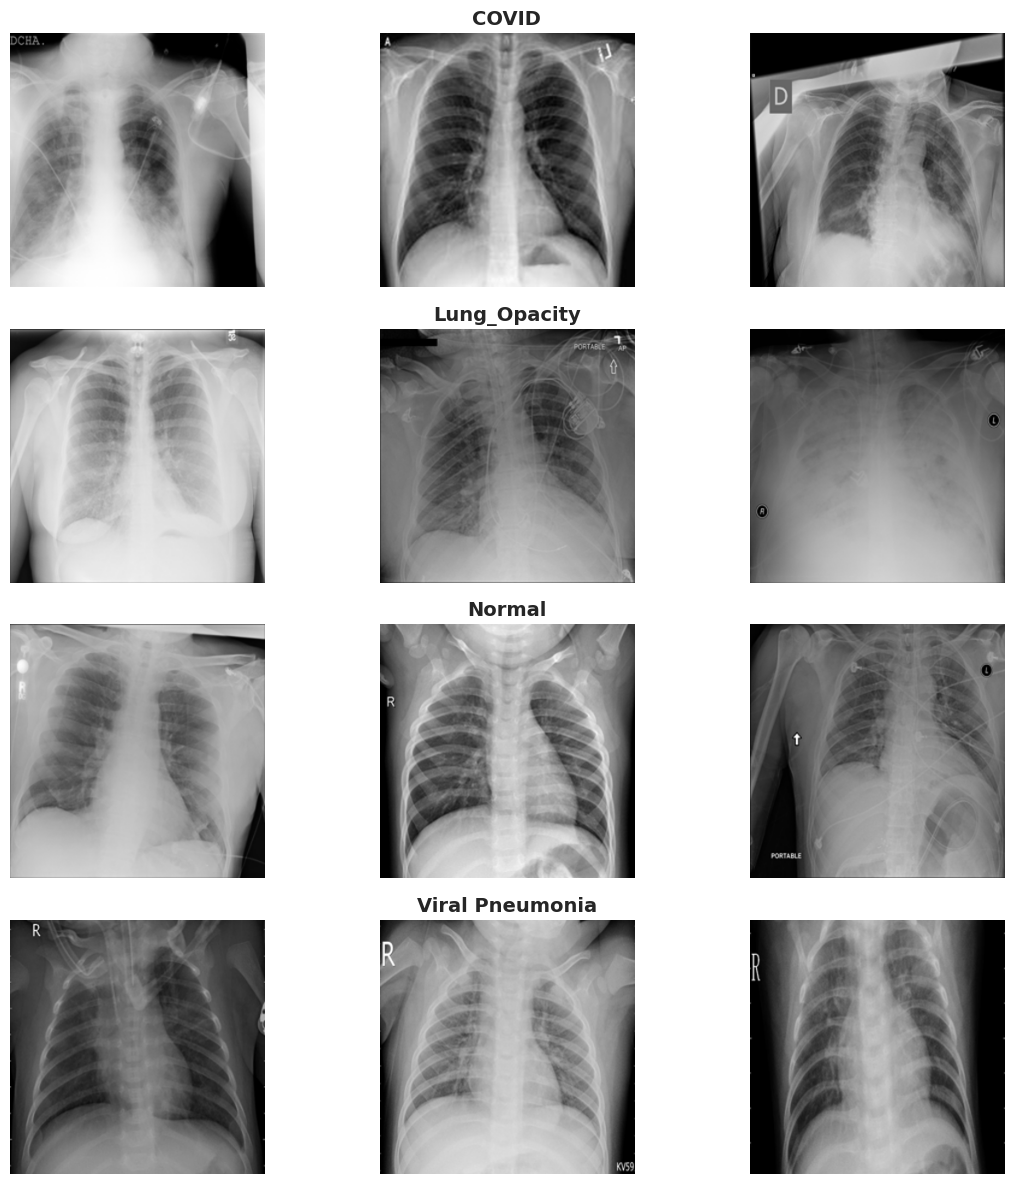

In [18]:
n_samples = 3
fig, m_axs = plt.subplots(4, n_samples, figsize=(4 * n_samples, 3 * 4))

for n_axs, (type_name, type_rows) in zip(m_axs, covidData.sort_values(['diag']).groupby('diag')):
    n_axs[1].set_title(type_name, fontsize=14, weight='bold')
    for c_ax, (_, c_row) in zip(n_axs, type_rows.sample(n_samples, random_state=1234).iterrows()):
        c_ax.imshow(cv2.imread(c_row['path']))
        c_ax.axis('off')
plt.tight_layout()
plt.show()

**Statistika piksela.** Da bismo uporedili klase po osvetljenosti i kontrastu, učitavamo sve slike u umanjenoj veličini (75 × 75 piksela), da stanu u memoriju i da obrada bude brža.

In [19]:
# Učitavamo sve slike umanjene na 75x75, u sivim nijansama (L), za statističku analizu
tqdm.pandas()
covidData['image'] = covidData['path'].progress_map(
    lambda x: np.asarray(Image.open(x).convert('L').resize((75, 75))))
print('Učitano slika:', len(covidData))

  0%|          | 0/21165 [00:00<?, ?it/s]

Učitano slika: 21165


Za svaku sliku računamo četiri broja:
* **mean**: prosečna osvetljenost (0 = crno, 255 = belo),
* **stedev**: standardna devijacija, mera kontrasta (veća vrednost = veće razlike između tamnih i svetlih delova),
* **max** i **min**: najsvetliji i najtamniji piksel.

In [20]:
# Za svaku sliku računamo jednostavne statistike piksela
imageEDA = covidData[['image', 'Class', 'path']].copy()
imageEDA['mean']   = imageEDA['image'].apply(np.mean)   # prosečna osvetljenost
imageEDA['stedev'] = imageEDA['image'].apply(np.std)    # standardna devijacija = kontrast
imageEDA['max']    = imageEDA['image'].apply(np.max)    # najsvetliji piksel
imageEDA['min']    = imageEDA['image'].apply(np.min)    # najtamniji piksel

imageEDA[['Class', 'mean', 'stedev', 'max', 'min']].groupby('Class').mean().round(1)

,mean,stedev,max,min
Class,,,,
Covid-19,139.5,54.2,228.0,6.4
Healthy,129.4,61.1,237.5,1.1
Lung Opacity,126.1,57.0,227.1,1.2
Viral Pneumonia,125.4,58.4,213.6,2.3


**Šta nam pokazuju proseci po klasama?**

* **Covid-19** se najviše izdvaja: najsvetliji je u proseku (mean 139.5), ima najmanji kontrast (stedev 54.2) i najveći minimum (6.4). To znači da COVID snimci retko imaju potpuno crne delove: često su isečeni bez crnih ivica, ili su obrađeni i kompresovani pre objavljivanja.
* **Healthy** ima najveći kontrast (61.1) i najsvetlije tačke (max 237.5).
* **Lung Opacity** i **Viral Pneumonia** su po proseku skoro isti (126.1 i 125.4). Viral Pneumonia ima najniži maksimum (213.6): snimci su u proseku „mekši”, bez jako svetlih delova.

Razlike nisu velike (prosek se kreće od 125 do 140), ali postoje. Važno pitanje je **odakle potiču**. Zamućenje pluća bi trebalo da poveća osvetljenost pluća, a Lung Opacity je ovde čak malo tamnija od zdravih pluća. To sugeriše da razlike u velikoj meri potiču od **izvora snimaka** (različite bolnice, aparati, način obrade), a ne samo od bolesti.

**KDE grafici** (Kernel Density Estimate) su „uglačani” histogrami: pokazuju koliko često se javlja koja vrednost. Što je kriva viša na nekom mestu, to više slika ima tu vrednost.

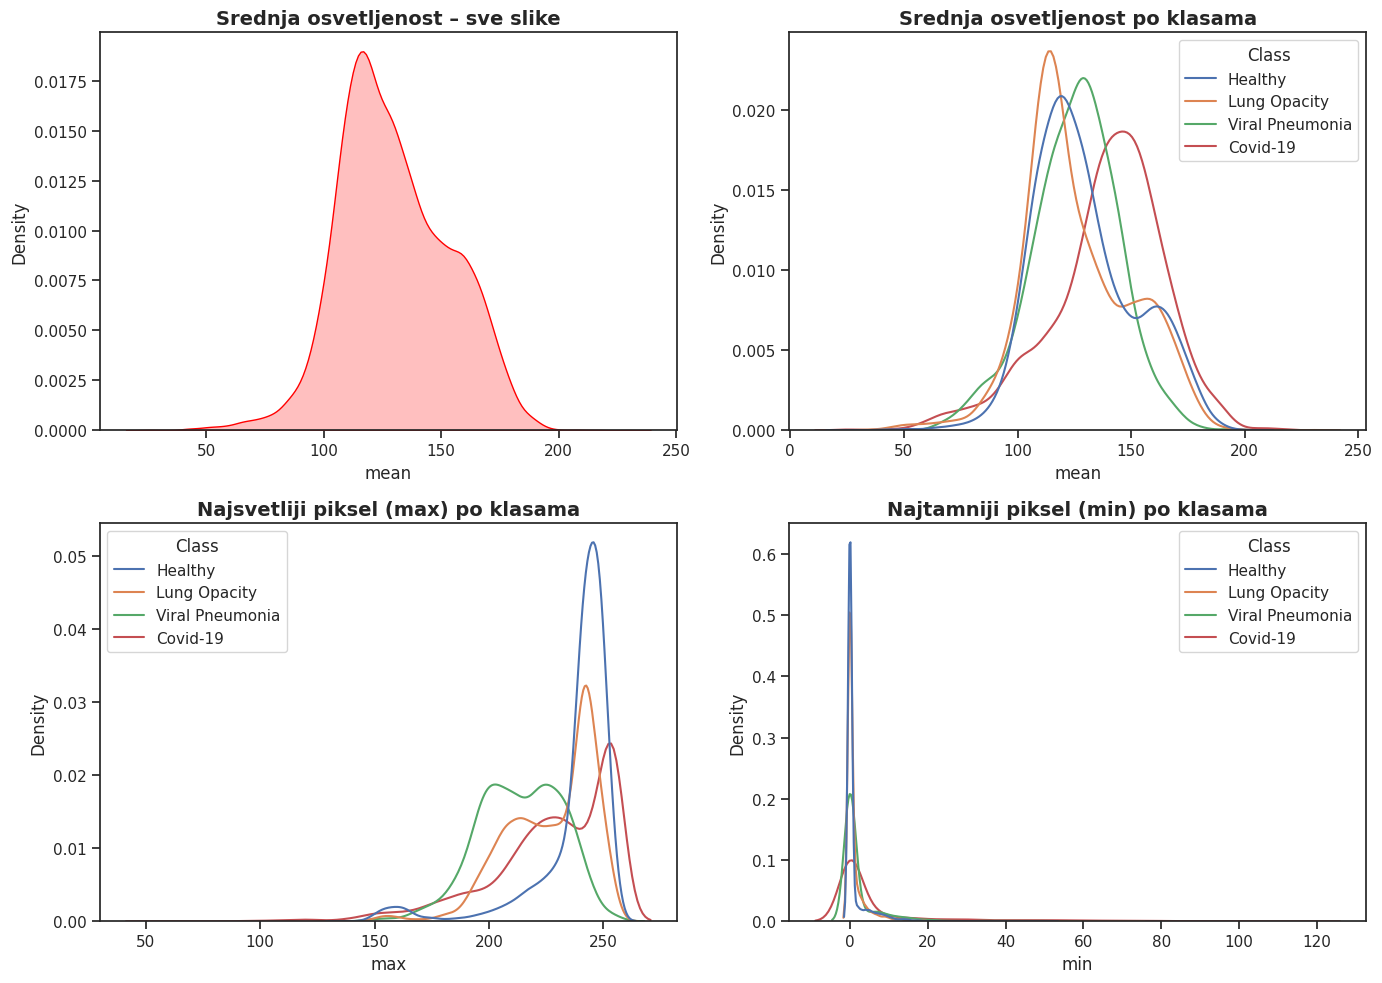

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1. srednja osvetljenost svih slika zajedno
sns.kdeplot(data=imageEDA, x='mean', color='red', fill=True, ax=axs[0, 0])
axs[0, 0].set_title('Srednja osvetljenost – sve slike', fontsize=14, weight='bold')

# 2–4. po klasama; common_norm=False: svaka klasa ima svoju krivu površine 1,
#      pa male klase nisu "spljoštene" uz dno grafika
for ax, kolona, naslov in [(axs[0, 1], 'mean', 'Srednja osvetljenost po klasama'),
                           (axs[1, 0], 'max',  'Najsvetliji piksel (max) po klasama'),
                           (axs[1, 1], 'min',  'Najtamniji piksel (min) po klasama')]:
    sns.kdeplot(data=imageEDA, x=kolona, hue='Class', common_norm=False, ax=ax)
    ax.set_title(naslov, fontsize=14, weight='bold')

plt.tight_layout()
plt.show()

**Tumačenje KDE grafika:**

**1. Srednja osvetljenost – sve slike.** Kriva ima vrh oko 118 i „rame” oko 155. To znači da u dataset-u postoje bar **dve grupe slika** različite osvetljenosti.

**2. Srednja osvetljenost po klasama.**
* **Covid-19** je jasno pomeren udesno: vrh je oko 147, dok su ostale klase između 113 i 130. COVID snimci su u proseku svetliji.
* **Healthy** i **Lung Opacity** imaju po **dva vrha**: glavni oko 115–120 i manji oko 160. Unutar iste klase postoje dve podgrupe snimaka, verovatno iz različitih izvora (ovo ćemo videti i na drugom času, kod DeTraC metode, koja klase deli na podklase).
* **Viral Pneumonia** ima jedan vrh, oko 130: najujednačenija klasa.

**3. Najsvetliji piksel (max).**
* **Healthy** ima uzak, visok vrh oko 245: skoro svi zdravi snimci imaju sličan maksimum, što ukazuje na ujednačen izvor.
* **Covid-19** ima vrh blizu 255: mnogi COVID snimci imaju potpuno bele, „pregorele” delove, verovatno zbog naknadne obrade.
* **Viral Pneumonia** retko prelazi 240; maksimum je između 200 i 230.

**4. Najtamniji piksel (min).** Skoro sve slike imaju minimum blizu 0, jer imaju crne ivice. Kod **Covid-19** kriva je niža i šira: više snimaka nema potpuno crne delove (isečeni su bez ivica).

**Zaključak:** klase se razlikuju po osnovnim osobinama slike (osvetljenost, kontrast, beli i crni delovi). Takve razlike nisu nužno posledica bolesti; često odražavaju **izvor i obradu snimaka**.

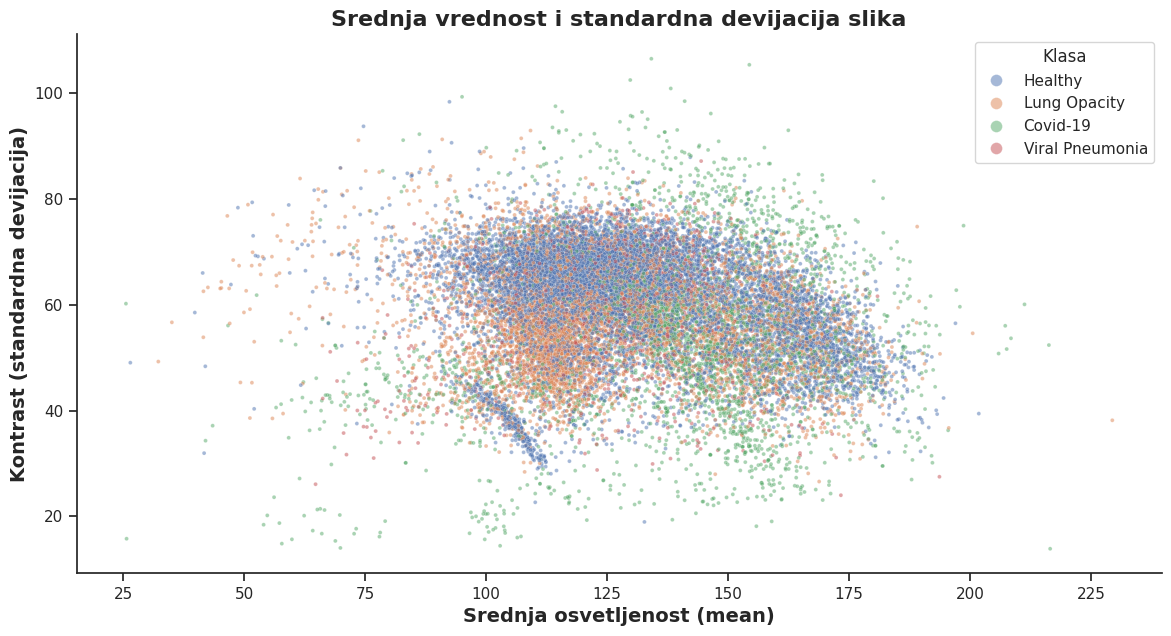

In [22]:
plt.figure(figsize=(14, 7))
sns.set(style="ticks", font_scale=1)

# Mešamo redosled tačaka, da nijedna klasa ne prekrije ostale samo zato što se crta poslednja
izmesano = imageEDA.sample(frac=1, random_state=0)
ax = sns.scatterplot(data=izmesano, x='mean', y='stedev', hue='Class', s=8, alpha=0.5,
                     hue_order=['Healthy', 'Lung Opacity', 'Covid-19', 'Viral Pneumonia'])
sns.despine(top=True, right=True)
ax.set_xlabel('Srednja osvetljenost (mean)', fontsize=14, weight='bold')
ax.set_ylabel('Kontrast (standardna devijacija)', fontsize=14, weight='bold')
plt.title('Srednja vrednost i standardna devijacija slika', fontsize=16, weight='bold')
plt.legend(title='Klasa', markerscale=3)
plt.show()

**Tumačenje grafika:**

* Klase se **jako preklapaju**: centralni oblak (osvetljenost 100–175, kontrast 45–75) sadrži slike svih klasa. Samo po osvetljenosti i kontrastu klase ne možemo razlikovati, i zato nam treba neuronska mreža koja gleda oblike i teksture.
* **Healthy** (plavo) je najbrojnija klasa i dominira centrom oblaka.
* **Lung Opacity** (narandžasto) je gušća levo dole: tamnije slike nižeg kontrasta (osvetljenost oko 110–120, kontrast oko 50).
* **Covid-19** (zeleno) je raširen udesno i nadole: više svetlih slika i više slika niskog kontrasta (kontrast ispod 40). Postoji i mala zasebna grupa COVID slika vrlo niskog kontrasta (osvetljenost oko 100, kontrast oko 20).
* Zanimljiva je **dijagonalna „traka” plavih tačaka** (osvetljenost 100–115, kontrast 30–45): grupa zdravih snimaka sa vrlo sličnim osobinama, verovatno iz istog izvora ili sa istom obradom.

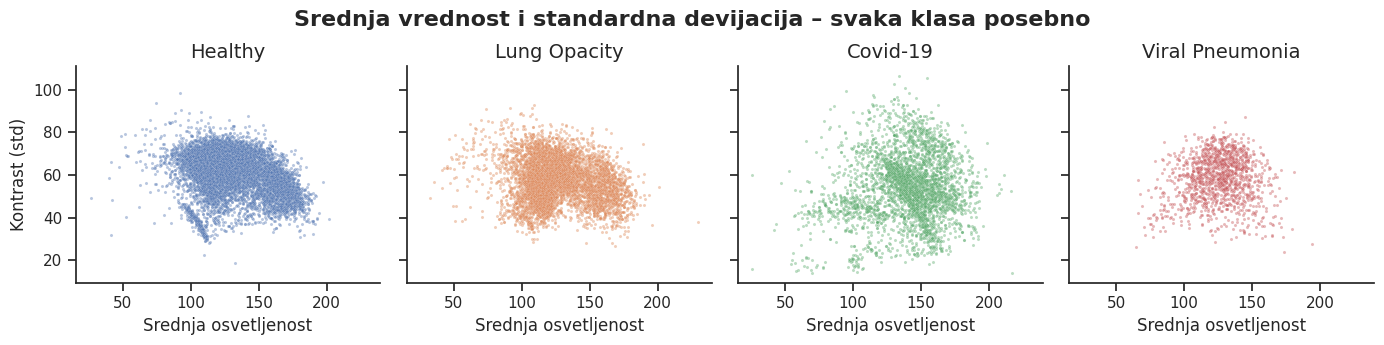

In [23]:
redosled = ['Healthy', 'Lung Opacity', 'Covid-19', 'Viral Pneumonia']
boje = dict(zip(redosled, sns.color_palette()[:4]))      # iste boje kao na prethodnom grafiku

g = sns.FacetGrid(imageEDA, col='Class', col_order=redosled, height=3.5,
                  hue='Class', hue_order=redosled, palette=boje)
g.map_dataframe(sns.scatterplot, x='mean', y='stedev', s=5, alpha=0.4)
g.set_titles(col_template='{col_name}', size=14)
g.set_axis_labels('Srednja osvetljenost', 'Kontrast (std)')
g.fig.suptitle('Srednja vrednost i standardna devijacija – svaka klasa posebno',
               fontsize=16, weight='bold')
g.fig.tight_layout()
g.fig.subplots_adjust(top=0.82)
plt.show()

**Svaka klasa posebno:**

* **Healthy:** glavni oblak ima dva dela (oko 120 i oko 165 po osvetljenosti), isto kao dva vrha na KDE grafiku. Izdvaja se i posebna **dijagonalna traka** (osvetljenost 95–115, kontrast 30–50): podgrupa zdravih snimaka koja se jasno razlikuje od ostalih, verovatno iz drugog izvora.
* **Lung Opacity:** kompaktan oblak, takođe sa dva dela (oko 115 i oko 160).
* **Covid-19:** **najrasutija klasa**, najveći raspon i po osvetljenosti i po kontrastu. Vidi se više odvojenih grupa: glavni oblak (osvetljenost 125–160), grupa niskog kontrasta (oko 20) i „rep” tamnijih slika levo. To je u skladu sa opisom dataset-a: COVID snimci su skupljeni iz čak četiri različita izvora, uključujući članke i internet.
* **Viral Pneumonia:** **najujednačenija klasa**, jedan kompaktan oblak. Snimci verovatno potiču iz jednog izvora.

**Zaključak:** klase nisu „jedna celina”. Unutar Healthy, Lung Opacity i posebno Covid-19 postoje podgrupe slika sa različitim osobinama. Ovo je upravo problem koji rešava **DeTraC** metoda sa drugog časa: ona svaku klasu automatski deli na podklase, pa model lakše uči.

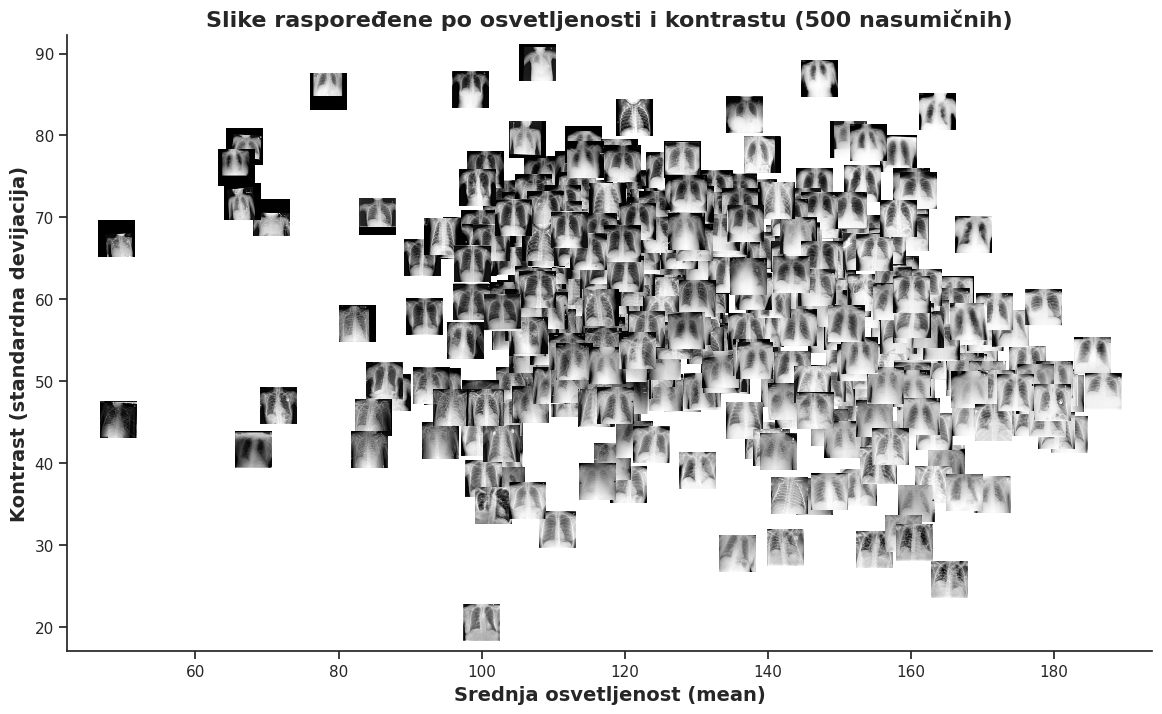

In [24]:
# 500 nasumičnih slika, prikazanih kao sličice na mestu svoje tačke (mean, stedev)
DF_sample = imageEDA.sample(n=500, random_state=1)

fig, ax = plt.subplots(figsize=(14, 8))
ax.scatter(DF_sample['mean'], DF_sample['stedev'], s=0)       # nevidljive tačke, samo za opseg osa
for x0, y0, slika in zip(DF_sample['mean'], DF_sample['stedev'], DF_sample['image']):
    ax.add_artist(AnnotationBbox(OffsetImage(slika, cmap='gray', zoom=0.35), (x0, y0), frameon=False))

sns.despine(top=True, right=True)
ax.set_xlabel('Srednja osvetljenost (mean)', fontsize=14, weight='bold')
ax.set_ylabel('Kontrast (standardna devijacija)', fontsize=14, weight='bold')
plt.title('Slike raspoređene po osvetljenosti i kontrastu (500 nasumičnih)', fontsize=16, weight='bold')
plt.show()

**Šta otkrivaju sličice?** Sada vidimo **zašto** su slike na određenom mestu na grafiku:

* **Levo (tamne slike, osvetljenost ispod 80):** snimci sa **velikim crnim ivicama**, gde grudni koš zauzima mali deo kadra. Crne ivice snižavaju prosek i povećavaju kontrast.
* **Desno (svetle slike, osvetljenost iznad 160):** snimci **usko isečeni** oko grudnog koša, bez crnih ivica, često „isprani” i svetli.
* **Dole (nizak kontrast, ispod 35):** **bledi, sivi snimci**, kao da su presnimljeni ili jako kompresovani.
* **U sredini:** „tipični” snimci, dobro eksponirani, sa malo crne pozadine oko tela.

**Zaključak EDA:** položaj slike na grafiku zavisi pre svega od **kadriranja, ekspozicije i obrade**, a ne od bolesti. To su tehničke osobine snimka. Zato je važna predobrada (ujednačavanje kontrasta, npr. CLAHE, i promena veličine), a pri tumačenju rezultata modela moramo se pitati: da li je model naučio bolest, ili način na koji je snimak napravljen?

#**Predložene metodologije na osnovu naučnih radova:**



# **1. Metodologija prvog rada**

*Khan, Rehman, Ahmed, Alfouzan, Alzahrani, Ahmad: Chest X-ray Classification for the Detection of COVID-19 Using Deep Learning Techniques, Sensors, 2022.*

**Modeli za višeklasnu klasifikaciju:**
* EfficientNetB1
* NasNetMobile
* MobileNetV2

Rad predlaže višeklasnu klasifikaciju rendgenskih snimaka grudnog koša u četiri klase: COVID-19, zamućenje pluća, normalna pluća i virusna pneumonija. Autori su koristili **isti Kaggle dataset kao mi**, pa njihove rezultate možemo direktno povezati sa našom analizom.

Autori ističu dva glavna izazova:
1. **Sličnost između klasa:** COVID-19, virusna pneumonija i druga zamućenja pluća na snimku mogu izgledati vrlo slično.
2. **Neravnoteža klasa:** javno dostupni skupovi podataka imaju mnogo više zdravih snimaka nego snimaka bolesti (što smo i sami videli u EDA).

Predložena metodologija prikazana je na dijagramu ispod:

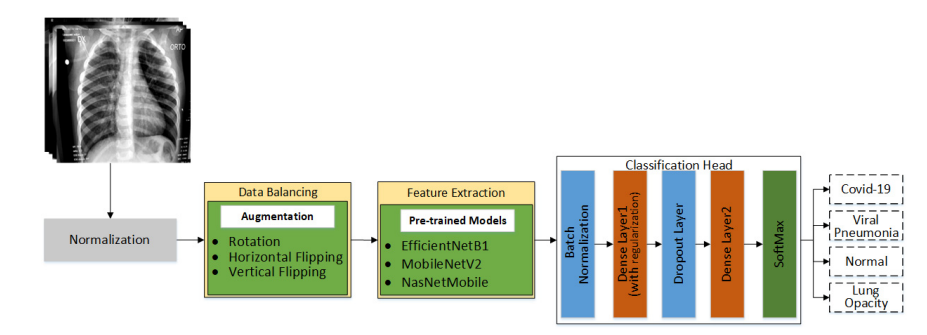

# **Predloženi korak 1: Predprocesiranje podataka**

Cilj predprocesiranja je da ublaži **neravnotežu klasa**. Neuravnotežen skup podataka negativno utiče na obuku: model postaje pristrasan prema najvećoj klasi, jer je najčešće viđa.

Autori su koristili dva postupka:

* **Normalizacija:** vrednosti piksela od 0 do 255 deljenjem sa 255 svode se na opseg od 0 do 1. Neuronske mreže stabilnije uče sa malim vrednostima.
* **Augmentacija:** od postojećih slika prave se nove, malo izmenjene verzije, rotacijom do 20° i horizontalnim i vertikalnim okretanjem. Augmentacija je primenjena **samo na manje klase** (COVID-19, zamućenje pluća i virusna pneumonija), da bi se njihov broj približio broju zdravih snimaka.

U ćeliji ispod prikazujemo kako izgleda augmentacija na po jednoj slici iz svake klase.

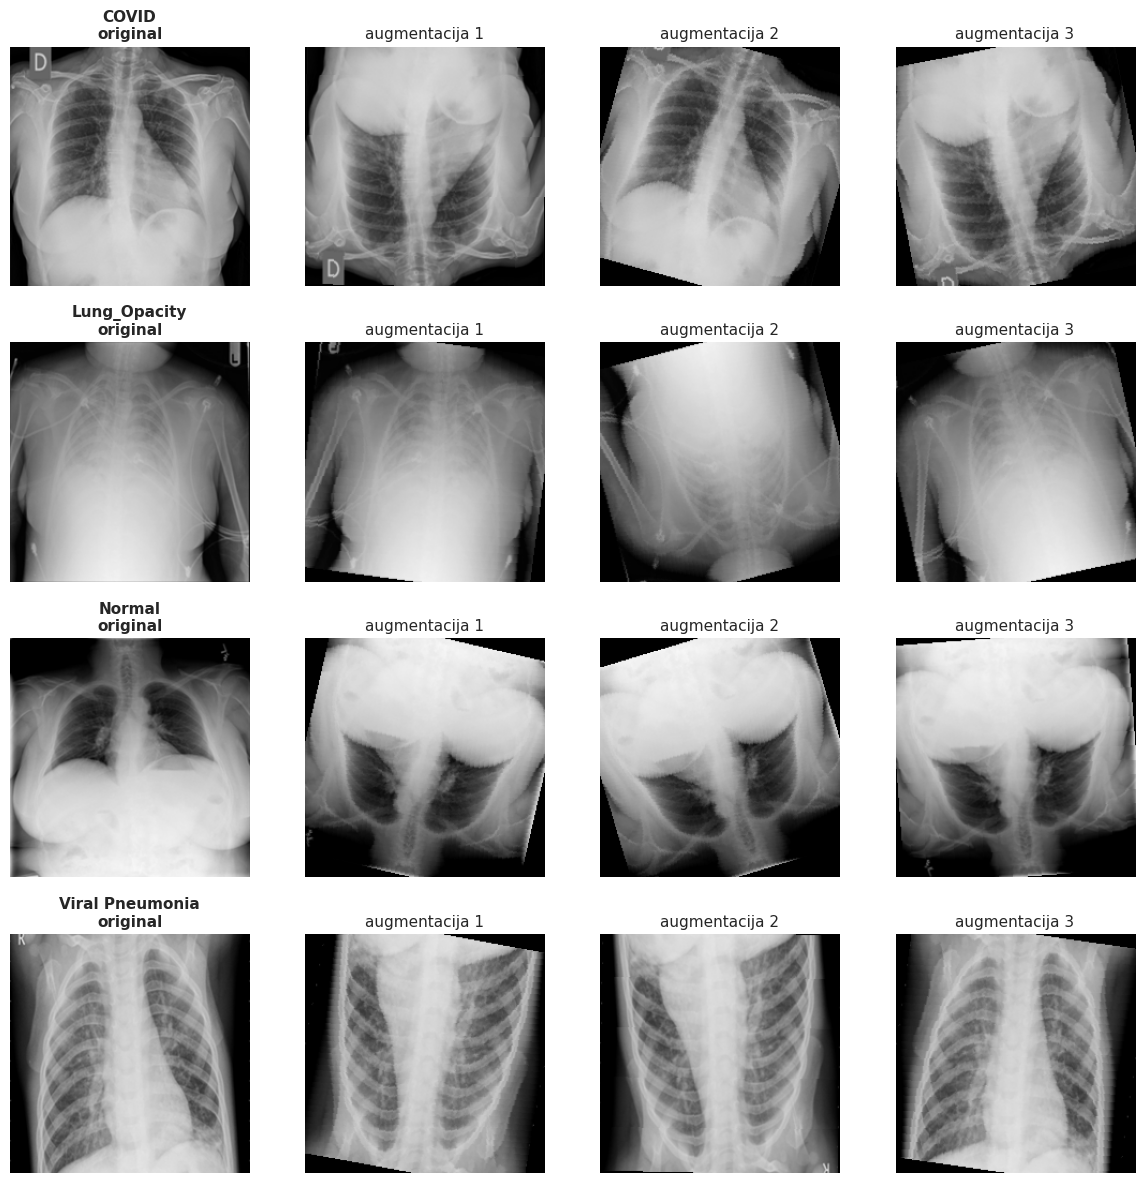

In [25]:
from torchvision import transforms

klase = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

# Transformacije kao u prvom radu: rotacija do 20° i horizontalno/vertikalno okretanje
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=20),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
])

random.seed(1)
fig, axs = plt.subplots(len(klase), 4, figsize=(12, 12))
for r, k in enumerate(klase):
    putanja_slike = random.choice(glob(os.path.join(data_dir, k, 'images', '*.png')))   # SAMO images
    img = Image.open(putanja_slike).convert('RGB')
    axs[r, 0].imshow(img.resize((224, 224)))
    axs[r, 0].set_title(f'{k}\noriginal', fontsize=11, weight='bold')
    for j in range(1, 4):
        axs[r, j].imshow(transform(img))     # svaki poziv daje drugačiju nasumičnu verziju
        axs[r, j].set_title(f'augmentacija {j}', fontsize=11)
    for ax in axs[r]:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Šta vidimo na augmentovanim slikama?**

* **Naopako okrenuti snimci** (glava dole, stomak gore) nastaju zbog vertikalnog okretanja. Takav rendgenski snimak se u stvarnosti nikada ne pravi.
* **Crni uglovi** nastaju zbog rotacije: delovi slike koji „izađu” iz kadra popune se crnom bojom.
* Na COVID snimku se u uglu vidi **slovo „D”**, a na drugim snimcima oznake L i R. Takve oznake zavise od bolnice i aparata, a ne od bolesti, i augmentacija ih samo premešta po slici.
* Snimak virusne pneumonije je **dečji** (manji, uži grudni koš). Pacijenti različitih klasa se razlikuju i po uzrastu.

**Kako se augmentacija koristi u praksi?**
* Augmentacija se radi **u letu (on-the-fly)**, tokom treniranja: u svakoj epohi model vidi malo drugačiju verziju iste slike. Nove slike ne čuvamo na disku.
* Augmentujemo **samo trening skup**. Validacioni i test skup ostaju originalni.
* Podela na trening, validacioni i test skup radi se **pre** augmentacije.

Da li su sve ove transformacije realne za rendgenski snimak grudnog koša?

Rotacija za nekoliko stepeni jeste, jer pacijent nikad ne stoji savršeno pravo. Horizontalno okretanje nije sasvim realno, jer je srce normalno na levoj strani. Vertikalno okretanje nikad se ne javlja u stvarnosti i može više da zbuni model nego da pomogne. Bolje je izostaviti ga, iako ga autori rada koriste.

**Drugi primer augmentacije: funkcije iz Keras-a**

Iste ideje možemo implementirati i pomoću OpenCV-a i Keras-a. Ovde prikazujemo četiri transformacije na istom COVID snimku:
* **flip:** horizontalno okretanje (ogledalska slika),
* **rotate:** rotacija za nasumičan ugao,
* **shear:** „iskošavanje” slike, kao da je gledamo pod uglom,
* **zoom:** uvećanje ili umanjenje.

In [26]:
def flip(img):
    # 1 = horizontalno okretanje (0 bi bilo vertikalno)
    return cv2.flip(img, 1)

def rotate(img, rotation_range=20):
    # rotacija za nasumičan ugao između -rotation_range i +rotation_range stepeni;
    # fill_mode='nearest' popunjava uglove najbližim pikselima umesto crnom bojom
    return tf.keras.preprocessing.image.random_rotation(
        img, rg=rotation_range, row_axis=0, col_axis=1, channel_axis=2, fill_mode='nearest')

def shear(img, shear_range=20):
    # iskošavanje za nasumičan ugao do shear_range stepeni
    return tf.keras.preprocessing.image.random_shear(
        img, shear_range, row_axis=0, col_axis=1, channel_axis=2)

def zoom(img, zoom_range=0.75):
    # (0.75, 0.75): faktor 0.75 po obe ose; kod Keras-a vrednost < 1 znači UVEĆANJE
    return tf.keras.preprocessing.image.random_zoom(
        img, (zoom_range, zoom_range), row_axis=0, col_axis=1, channel_axis=2)

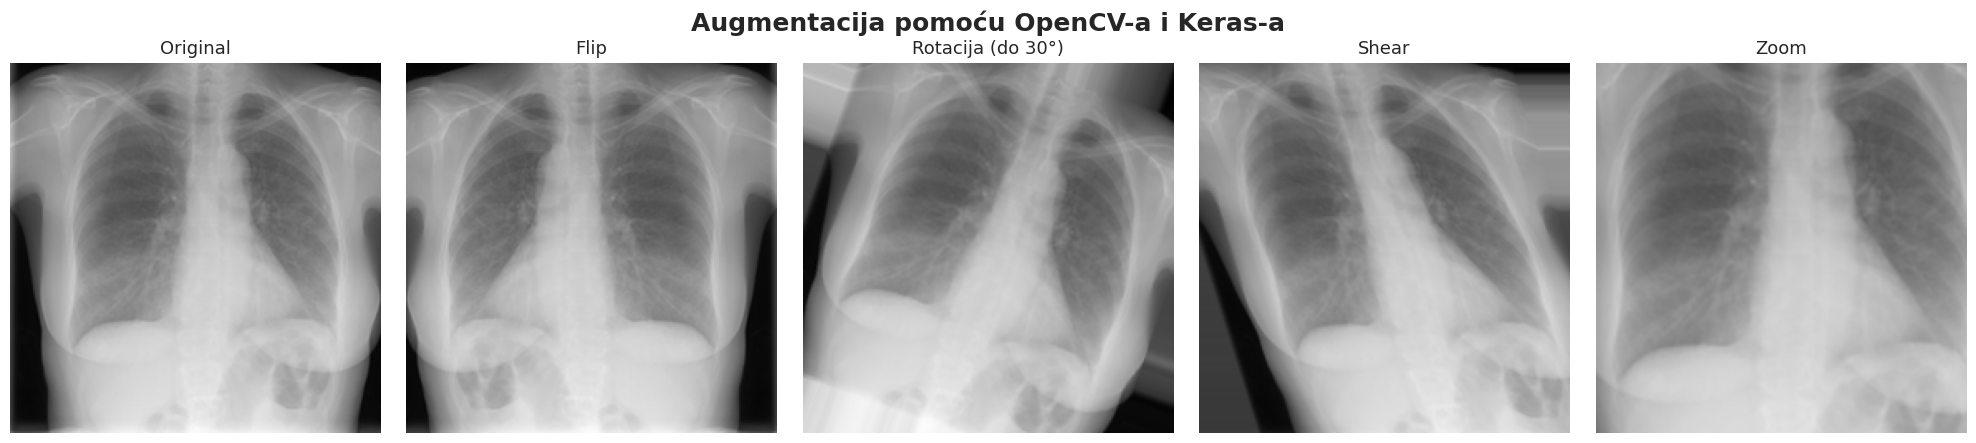

In [27]:
base_image = covid_example

augmentacije = {
    'Original': base_image,
    'Flip': flip(base_image),
    'Rotacija (do 30°)': rotate(base_image, rotation_range=30),
    'Shear': shear(base_image),
    'Zoom': zoom(base_image),
}

fig, axs = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, (naziv, slika) in zip(axs, augmentacije.items()):
    ax.imshow(slika)
    ax.set_title(naziv, fontsize=13)
    ax.axis('off')
fig.suptitle('Augmentacija pomoću OpenCV-a i Keras-a', fontsize=18, weight='bold')
plt.tight_layout()
plt.show()

**Šta vidimo?**
* **Flip:** srce je sada na **desnoj** strani, a gasni mehur želuca (tamna površina dole) prešao je sa jedne strane na drugu. Takav snimak je anatomski nerealan.
* **Rotacija:** slika je blago zarotirana, a uglovi su popunjeni „razvučenim” pikselima sa ivice (`fill_mode='nearest'`), umesto crnom bojom kao kod torchvision-a. Na levoj ivici i dole se vide te pruge.
* **Shear:** na ovom primeru je iskošavanje jedva primetno; ugao je nasumičan, pa je ovog puta ispao mali.
* **Zoom:** slika je uvećana, pa su ramena, vrh pluća i stomak isečeni. Zoom ne sme da bude prevelik, jer možemo izgubiti baš deo pluća na kome je promena.

Pokrenite ćeliju više puta: rotacija, shear i zoom su nasumični i svaki put daju drugačiju sliku. Flip je uvek isti.

# **Predloženi korak 2: Odabir CNN modela**

Autori su izabrali tri relativno mala, „laka” modela:

**EfficientNetB1**

EfficientNet je porodica modela B0–B7. Osnovni model **B0** pronađen je automatskom pretragom arhitekture, a veći modeli (B1, B2, …) dobijeni su **kompozitnim skaliranjem** (compound scaling): mreža se istovremeno i u ravnoteži povećava po širini (broj kanala), dubini (broj slojeva) i rezoluciji ulazne slike. EfficientNetB1 je, dakle, malo uvećana verzija B0 i koristi ulazne slike veličine **240 × 240** piksela.

Osnovni gradivni blok je **MBConv**, invertovani rezidualni blok koji smanjuje broj parametara. Njegov deo, **squeeze-and-excitation** blok, uči koliko je koji kanal važan i dodeljuje kanalima različite težine.

EfficientNet koristi **swish** aktivacionu funkciju: swish(x) = x · sigmoid(x). Za razliku od ReLU, koja sve negativne vrednosti postavlja na nulu, swish propušta i male negativne vrednosti, što pomaže učenju.

**MobileNetV2**

Lagan model namenjen mobilnim uređajima (već smo ga koristili u prvom case study-ju). Sastoji se od **17 bottleneck blokova**, ukupno 53 sloja. Blokovi koriste **dubinske (depthwise)** i **tačkaste (pointwise, 1×1)** konvolucije, ReLU6 aktivacije i batch normalization.

**NasNetMobile**

NASNet znači **Neural Architecture Search Network**: arhitekturu ove mreže nije osmislio čovek, nego ju je pronašao algoritam koji je isprobavao različite kombinacije slojeva. Mreža se sastoji od dva tipa ćelija: **normalnih ćelija**, koje izdvajaju karakteristike i ne menjaju dimenziju, i **redukcijskih ćelija**, koje dimenziju mape karakteristika smanjuju dva puta. Redukcijske ćelije se smenjuju sa grupama od po četiri normalne ćelije.

| Model | Broj parametara (približno) | Ulazna slika |
|---|---|---|
| MobileNetV2 | 3.5 miliona | 224 × 224 |
| NasNetMobile | 5.3 miliona | 224 × 224 |
| EfficientNetB1 | 7.8 miliona | 240 × 240 |

Poređenja radi, ResNet50 ima oko 25 miliona, a VGG19 oko 144 miliona parametara.

# **Predloženi korak 3: Re-treniranje modela – Transfer Learning**

Sva tri modela su prethodno trenirana na skupu podataka **ImageNet** (oko 1,2 miliona slika, 1000 klasa), a zatim dotrenirana na rendgenskim snimcima pomoću **transfer learning-a**.

CNN se može obučiti na dva načina:
1. **Od nule (end-to-end):** sve težine se uče iz početka. Za to je potreban ogroman broj označenih slika, što je u medicini nepraktično, jer slike mora da označi lekar.
2. **Transfer learning:** koristimo mrežu koja je već naučila da prepoznaje ivice, teksture i oblike na velikom skupu slika, i prilagođavamo je našem zadatku. Potrebno je mnogo manje slika i vremena za obuku.

Transfer learning ima tri režima:

| Režim | Šta se trenira | Kada se koristi |
|---|---|---|
| **Shallow tuning** | samo nova klasifikaciona glava; baza je zamrznuta | malo podataka, brzo treniranje |
| **Fine-tuning** | glava + poslednji slojevi baze | srednje mnogo podataka (videli smo u case study 1) |
| **Deep tuning** | cela mreža, sa malim learning rate-om | dovoljno podataka; obično najbolji rezultat, ali najsporije |

Ove pojmove ćemo ponovo sresti u trećem radu (DeTraC).

Taj koncept je prikazan na slici:

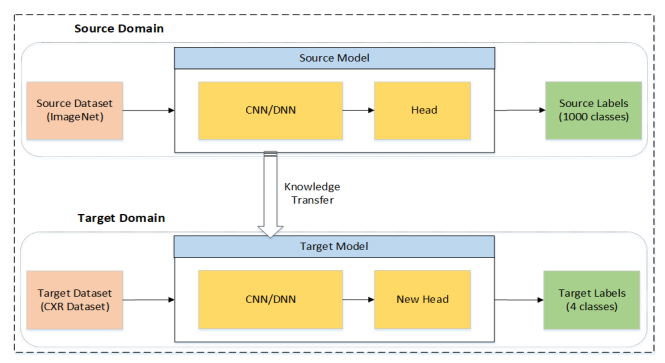

# **Predloženi korak 4: Treniranje i testiranje modela**

**Podela podataka**

Skup podataka je podeljen na tri dela, u odnosu **70 : 20 : 10**:
* **trening skup (70%):** na njemu model uči,
* **validacioni skup (20%):** prati se tokom treniranja, za izbor najbolje epohe i podešavanje parametara,
* **test skup (10%):** model ga ne vidi tokom treniranja; na njemu se meri konačan rezultat.

**Learning rate i raspored učenja**

Početni learning rate je **0.0001**. Umesto jedne vrednosti tokom celog treniranja, koristi se **raspored učenja (learning rate scheduler)**: kad god validacioni gubitak prestane da opada, learning rate se **deli sa 2** (isto što radi `ReduceLROnPlateau` u Keras-u, iz prvog case study-ja).

Mali learning rate je važan kod pretreniranih modela: težine se menjaju polako, pa se čuva znanje naučeno na ImageNet-u. Prevelik learning rate ubrzava obuku, ali može da „pokvari” pretrenirane težine.

**Nova klasifikaciona glava**

**Klasifikaciona glava** je završni deo mreže koji naučene karakteristike pretvara u verovatnoće za svaku klasu. Originalna glava (za 1000 klasa ImageNet-a) uklonjena je iz sva tri modela i zamenjena novom, redom:

1. pretrenirana baza (EfficientNetB1 / NasNetMobile / MobileNetV2)
2. Global Average Pooling
3. Batch Normalization
4. Dense 256 (Dense layer 1, sa L2 regularizacijom)
5. Dropout
6. Dense 4 sa softmax aktivacijom (Dense layer 2: po jedna verovatnoća za svaku klasu)

* **Batch normalization** normalizuje izlaze prethodnog sloja; ubrzava konvergenciju i poboljšava tačnost.
* **Dropout** tokom treniranja nasumično isključuje deo neurona, pa model manje pamti trening slike (smanjuje overfitting).
* Optimizator je **Adam**.

**Rezultati treniranja za EfficientNetB1**

Na grafiku ispod: trening tačnost raste skoro do 100%, a validaciona se ustali na oko 96%. Razmak između krivih je mali, pa overfitting nije izražen. Najbolja validaciona tačnost postignuta je u **20. epohi**, a najmanji validacioni gubitak u **18. epohi** (plave tačke).

**Prikaz rezultata treniranja: tačnost(accuracy) i gubitak(loos) za model EfficientNetB1**


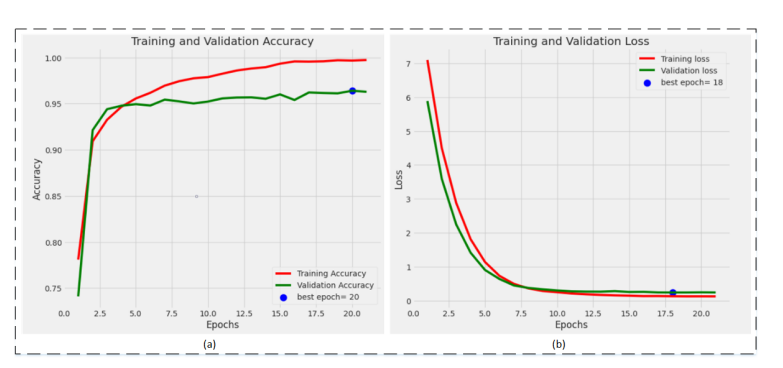

# **Predloženi korak 5: Analiza rezultata**

Modeli su ocenjeni na test skupu pomoću više metrika:
* **tačnost (accuracy):** udeo svih tačno klasifikovanih slika,
* **preciznost (precision):** od svih slika koje je model proglasio nekom klasom, koliko ih zaista pripada toj klasi,
* **osetljivost (sensitivity, recall):** od svih slika neke klase, koliko ih je model pronašao,
* **F1 mera:** harmonijska sredina preciznosti i osetljivosti.

U radu se pominju i stopa lažno pozitivnih (FPR) i specifičnost, ali one nisu prikazane u tabeli rezultata.

Rezultati (strategija II, sa batch normalization, dropout i L2 regularizacijom):
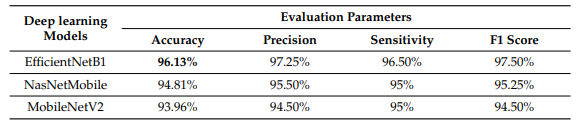

Najbolji je **EfficientNetB1** sa tačnošću **96.13%**, zatim NasNetMobile (94.81%) i MobileNetV2 (93.96%). Razlike između modela su male, oko 2 procentna poena.



**Matrice konfuzije (u procentima po stvarnoj klasi):**


* **EfficientNetB1**

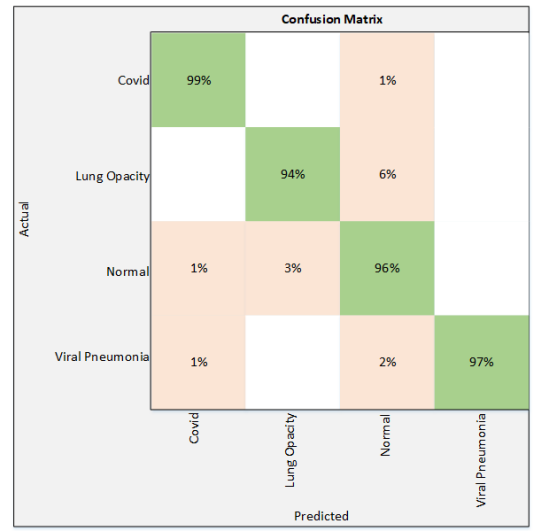


* **NasNetMobile**


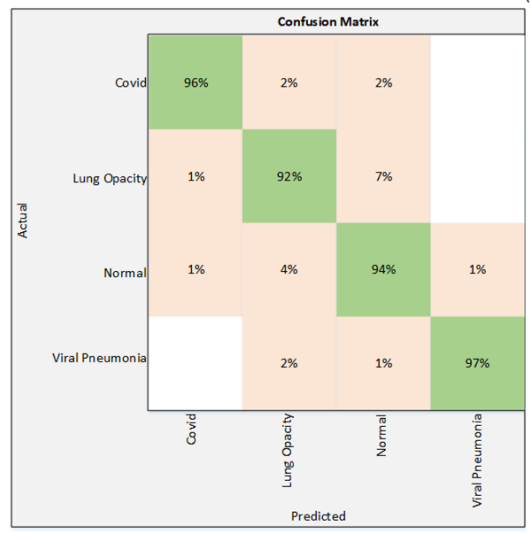

* **MobileNetV2**


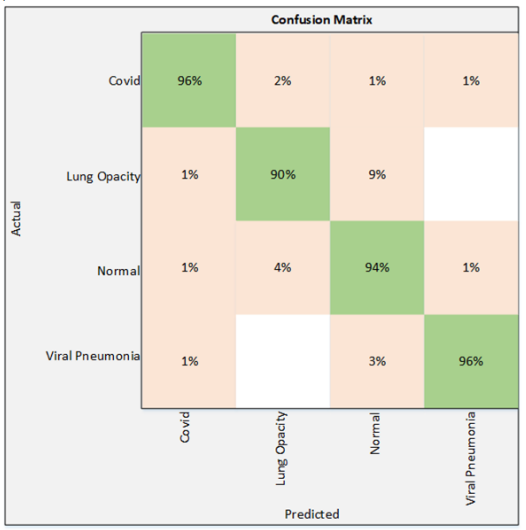

**Tumačenje matrica konfuzije** (redovi su stvarne klase, kolone predviđene):

| Klasa | EfficientNetB1 | NasNetMobile | MobileNetV2 |
|---|---|---|---|
| Covid | 99% | 96% | 96% |
| Lung Opacity | 94% | 92% | 90% |
| Normal | 96% | 94% | 94% |
| Viral Pneumonia | 97% | 97% | 96% |

* Kod sva tri modela **najslabije je prepoznato zamućenje pluća (Lung Opacity)**, i to se najčešće meša sa **zdravim plućima**: 6%, 7% i 9% zamućenja model je proglasio zdravim plućima.
* **COVID i virusna pneumonija** se prepoznaju najbolje, kod svih modela 96% ili više.

# **Predloženi korak 6: Zaključak**

Autori su uporedili dve strategije treniranja:

* **Strategija I:** sva tri modela su dotrenirana transfer learning-om na normalizovanim i augmentovanim podacima, sa jednostavnom klasifikacionom glavom, **bez** batch normalization, dropout sloja i L2 regularizacije.
* **Strategija II:** isti modeli, ali klasifikaciona glava sadrži **batch normalization i dropout**, a Dense layer 1 je regularizovan **L2 regularizacijom** (weight decay), koja kažnjava velike težine.



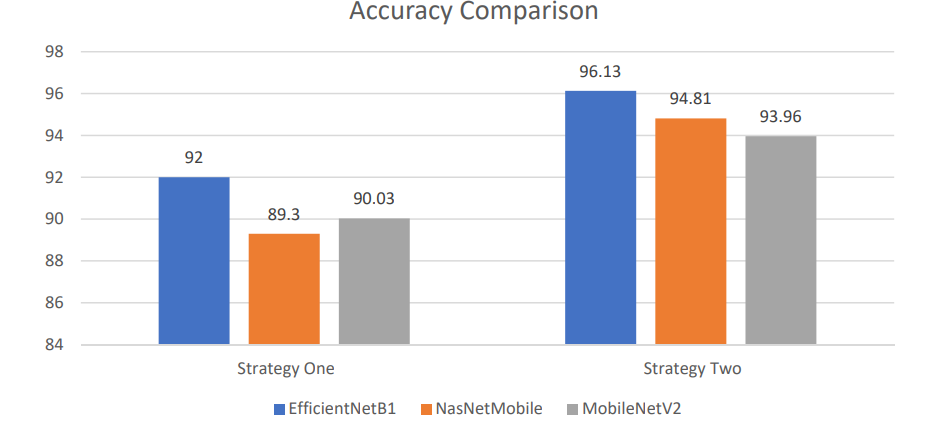


| Model | Strategija I | Strategija II | Poboljšanje |
|---|---|---|---|
| EfficientNetB1 | 92.00% | **96.13%** | +4.1 |
| NasNetMobile | 89.30% | 94.81% | +5.5 |
| MobileNetV2 | 90.03% | 93.96% | +3.9 |

**Zaključak prvog rada:**
* Strategija II je poboljšala **sva tri modela** za 4 do 5.5 procentnih poena.
* Razlike između arhitektura su manje (2 do 3 poena) od razlike koju donosi regularizacija.
* **Pouka:** dobro podešena klasifikaciona glava i regularizacija (batch normalization, dropout, L2) podjednako su važne kao izbor osnovnog modela.



# POČETAK DRUGOG ČASA

Ako je sesija restartovana, pokrenuti ćeliju ispod: ona učitava biblioteke i preuzima dataset (ako ga nema).

In [1]:
import os, random, shutil
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import tensorflow as tf

if not os.path.exists('/content/COVID-19_Radiography_Dataset'):
    import kagglehub
    putanja = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")
    os.symlink(os.path.join(putanja, 'COVID-19_Radiography_Dataset'), '/content/COVID-19_Radiography_Dataset')

print(os.listdir('/content/COVID-19_Radiography_Dataset'))
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
['Lung_Opacity.metadata.xlsx', 'Normal.metadata.xlsx', 'README.md.txt', 'COVID.metadata.xlsx', 'Normal', 'Lung_Opacity', 'Viral Pneumonia.metadata.xlsx', 'Viral Pneumonia', 'COVID']
TensorFlow 2.21.0 | GPU: []


# **2. Metodologija drugog rada: CovXNet**

*Mahmud, Rahman, Fattah: CovXNet: A multi-dilation convolutional neural network for automatic COVID-19 and other pneumonia detection from chest X-ray images with transferable multi-receptive feature optimization, Computers in Biology and Medicine, 2020.*

**Problem:** na početku pandemije (2020) bilo je dostupno vrlo malo COVID-19 snimaka, premalo za treniranje duboke mreže od nule.

**Ideja rada, u četiri koraka:**

1. **Multi-dilaciona konvolucija.** CovXNet koristi dubinske (depthwise) konvolucije sa različitim stepenom **dilatacije**. Dilatirana konvolucija ima „rupe” između elemenata filtera, pa filter 3×3 „vidi” veće područje slike, a nema više parametara. Paralelne grane sa različitim dilatacijama hvataju i sitne detalje i krupne strukture (npr. zamućenja koja zahvataju veći deo pluća).
2. **Transfer learning sa srodnog zadatka.** Mreža se prvo trenira na većem skupu od **5856 snimaka** (zdrava pluća, virusna i bakterijska pneumonija), a zatim se dotrenira na malom skupu COVID-19 snimaka. Za razliku od ImageNet-a, izvorni zadatak je iz istog domena: rendgenski snimci pluća.
3. **Stacking (ansambl).** Trenira se više varijanti mreže za različite veličine ulazne slike, a njihove odluke kombinuje dodatni model.
4. **Lokalizacija.** Gradijentnom metodom (slično Grad-CAM-u) dobija se mapa koja pokazuje koji delovi snimka su najviše uticali na odluku, pa lekar može da proveri da li model gleda u pluća.

**Rezultati iz rada:**

| Zadatak | Tačnost |
|---|---|
| COVID-19 / normalno | 97.4% |
| COVID-19 / virusna pneumonija | 96.9% |
| COVID-19 / bakterijska pneumonija | 94.7% |
| sve 4 klase zajedno | 90.2% |

Tačnost opada kako zadatak postaje teži: najlakše je razlikovati COVID od zdravih pluća, a najteže četiri klase odjednom.

Ovaj rad **nije** koristio naš Kaggle dataset, pa njegove brojeve ne možemo direktno porediti sa prvim radom.

**Mali eksperiment: šta radi dilatacija?**

Upoređujemo običnu konvoluciju 3×3 i dilatiranu (`dilation_rate=2`). Broj parametara je isti, a područje koje filter „vidi” je veće.

obicna_3x3           parametara:  80   filter pokriva: 3x3 piksela
dilatirana_3x3_d2    parametara:  80   filter pokriva: 5x5 piksela


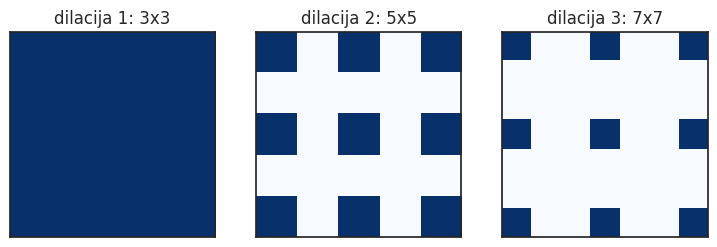

In [28]:
from tensorflow.keras import layers

ulaz = tf.keras.Input(shape=(64, 64, 1))
obicna     = layers.Conv2D(8, 3, padding='same', dilation_rate=1, name='obicna_3x3')
dilatirana = layers.Conv2D(8, 3, padding='same', dilation_rate=2, name='dilatirana_3x3_d2')
obicna(ulaz); dilatirana(ulaz)

for sloj, d in [(obicna, 1), (dilatirana, 2)]:
    polje = 3 + (3 - 1) * (d - 1)            # efektivna veličina filtera
    print(f'{sloj.name:20s} parametara: {sloj.count_params():3d}   filter pokriva: {polje}x{polje} piksela')

# Vizuelno: koje piksele koristi filter (plavo = koristi, belo = preskače)
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, d in zip(axs, [1, 2, 3]):
    n = 3 + 2 * (d - 1)
    maska = np.zeros((n, n)); maska[::d, ::d] = 1
    ax.imshow(maska, cmap='Blues', vmin=0, vmax=1)
    ax.set_title(f'dilacija {d}: {n}x{n}'); ax.set_xticks([]); ax.set_yticks([])
plt.show()

Oba sloja imaju isti broj parametara (80 = 3·3·1·8 težina + 8 bias-a), ali obična konvolucija pokriva 3×3, a dilatirana 5×5 piksela. Na slikama su plavi kvadrati pikseli koje filter koristi: svih 9 težina se „raširi” preko većeg područja.

**Zašto je to korisno za rendgenske snimke?** Neke promene su sitne, a neka zamućenja zahvataju veliki deo pluća. Paralelne grane sa različitim dilatacijama vide i sitne detalje i krupne strukture, bez povećanja broja parametara.


# **3. Metodologija trećeg rada: DeTraC**

*Abbas, Abdelsamea, Gaber: Classification of COVID-19 in chest X-ray images using DeTraC deep convolutional neural network, Applied Intelligence, 2021.*

Autori predlažu duboku konvolucionu mrežu **DeTraC** (*Decompose, Transfer and Compose*: razloži, prenesi, sastavi) za klasifikaciju rendgenskih snimaka pacijenata sa COVID-19.

**Osnovna ideja:** slike unutar jedne klase nisu uvek slične. Na primer, „COVID” snimci mogu da dolaze sa dva različita aparata, ili da prikazuju rani i kasni stadijum bolesti. Takva klasa je **nepravilna** (heterogena), i modelu je teško da za nju nauči jednu granicu. (Ovo smo videli i u našoj EDA: unutar klasa Healthy, Lung Opacity i Covid-19 postoje podgrupe slika.)

DeTraC zato:
1. **razloži** (decompose) svaku klasu na podklase, automatski, grupisanjem sličnih slika;
2. **prenese** (transfer) znanje pretrenirane mreže i nauči da razlikuje podklase;
3. **sastavi** (compose) podklase nazad u originalne klase za konačnu odluku.


Na sledećoj slici je prikazana metodologija korišćena u ovom naučnom radu:



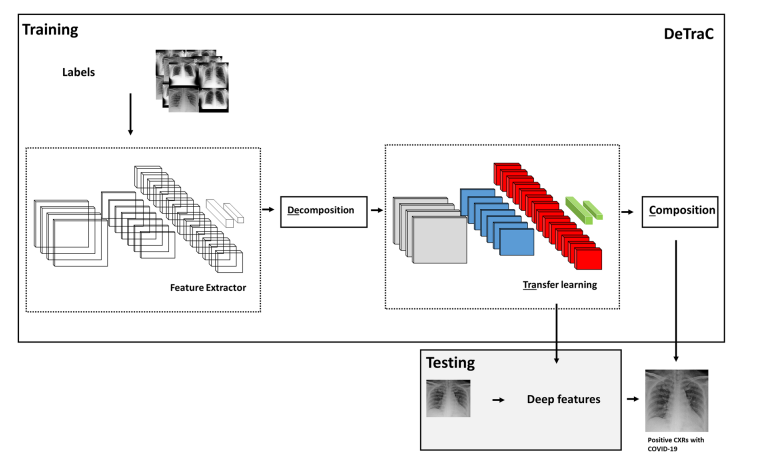


# **Predloženi korak 1: Predprocesiranje podataka**

Autori su imali samo **196 originalnih snimaka** u tri klase: 80 normalnih, 105 COVID-19 i 11 SARS.

Da bi dobili više uzoraka, primenili su augmentaciju:
* okretanje gore-dole i levo-desno (flip),
* translaciju (pomeranje),
* rotaciju za pet nasumičnih uglova.

Tako je nastalo ukupno **1764 uzorka**. Zatim je primenjena **modifikacija histograma**, da bi se poboljšao kontrast svake slike.

 **Važno:** autori su podatke podelili na trening i test skup **posle** augmentacije. Tada se slika i njena okrenuta ili rotirana kopija mogu naći jedna u trening, a druga u test skupu, pa se model testira na gotovo istoj slici koju je već video. Rezultat je preterano optimističan; to se zove **curenje podataka (data leakage)**.

**Pravilo:** podela na trening, validacioni i test skup uvek se radi **pre** augmentacije, i augmentuje se samo trening skup.


Pre nego što se donese odluka kojom tehnikom će se poboljšati kontrast, treba da se proveri koja metoda daje bolji rezultat za sliku ili tip slika — CLAHE ili global histogram equalization.

Upoređivanje histograma normalizacije i CLAHE na slikama gde se nalaze pluća obolela od COVID-19:

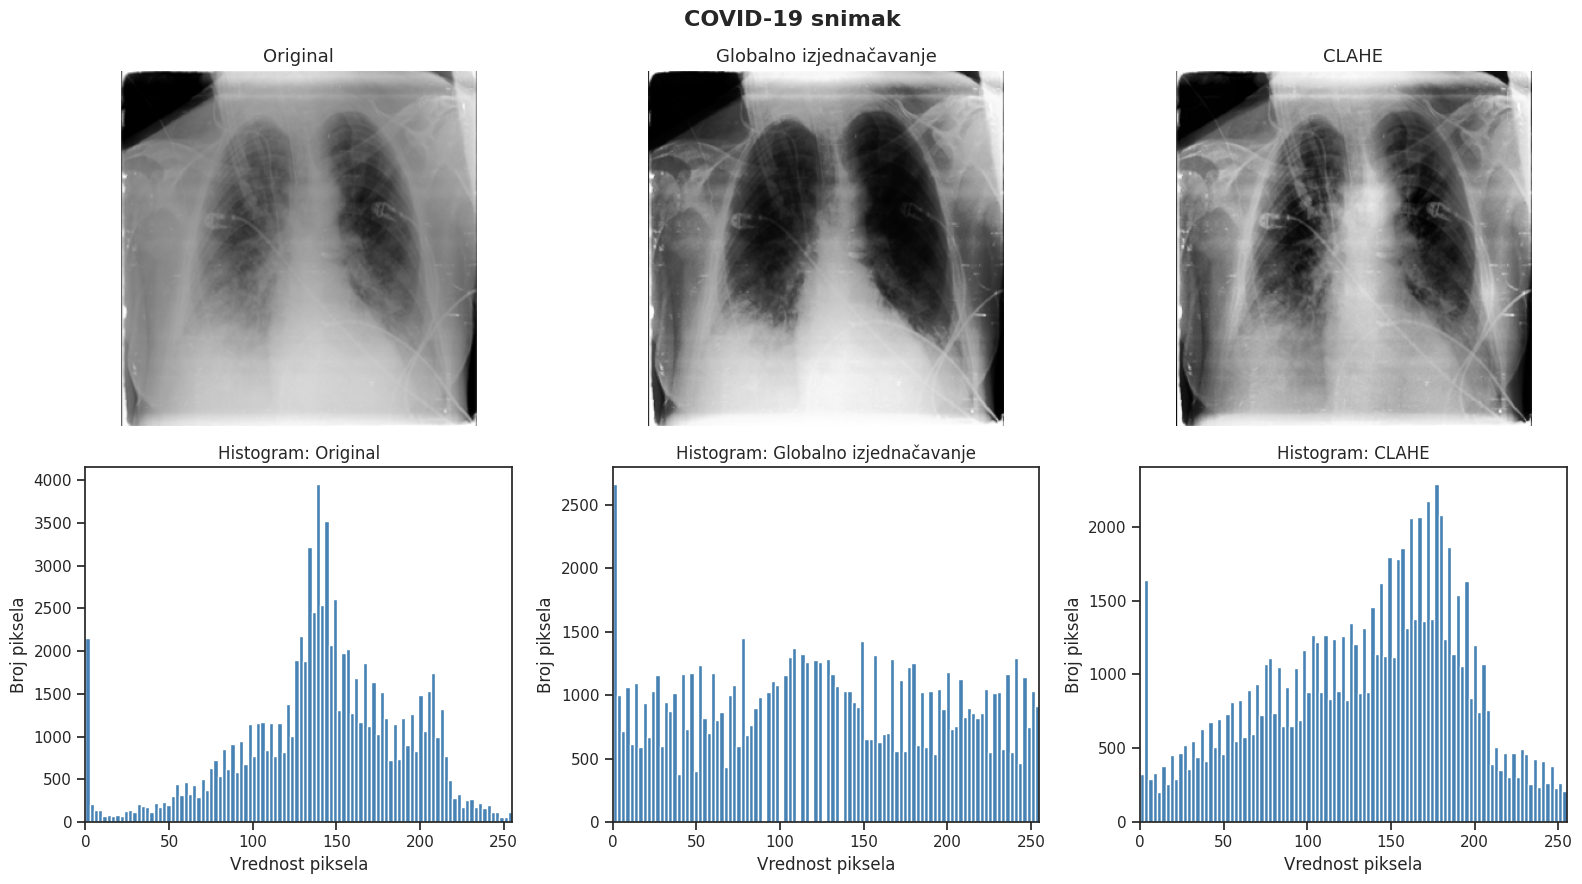

In [30]:
def uporedi_kontrast(putanja, naslov):
    """Poredi globalno izjednačavanje histograma i CLAHE na jednom snimku."""
    siva = cv2.imread(putanja, cv2.IMREAD_GRAYSCALE)
    globalno = cv2.equalizeHist(siva)                                       # globalno izjednačavanje
    clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4, 4)).apply(siva)   # CLAHE

    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    # gornji red: slike
    for ax, slika, ime in zip(axs[0], [siva, globalno, clahe],
                              ['Original', 'Globalno izjednačavanje', 'CLAHE']):
        ax.imshow(slika, cmap='gray'); ax.set_title(ime, fontsize=13); ax.axis('off')
    # donji red: histogrami
    for ax, slika, ime in zip(axs[1], [siva, globalno, clahe],
                              ['Original', 'Globalno izjednačavanje', 'CLAHE']):
        ax.hist(slika.ravel(), bins=100, range=(0, 255), color='steelblue')
        ax.set_title(f'Histogram: {ime}', fontsize=12); ax.set_xlim(0, 255)
        ax.set_xlabel('Vrednost piksela'); ax.set_ylabel('Broj piksela')
    fig.suptitle(naslov, fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()

uporedi_kontrast('/content/COVID-19_Radiography_Dataset/COVID/images/COVID-3.png',
                 'COVID-19 snimak')

**Šta vidimo?**

* **Original:** histogram je skupljen u uskom opsegu (vrh oko 130–150), pa je slika „isprana” i siva.
* **Globalno izjednačavanje:** histogram je skoro **ravan**, jer su vrednosti razvučene preko celog opsega. Kontrast je jak, ali pluća su skoro crna, a donji delovi pluća i srce skoro beli. Fini detalji, upravo u plućima, delimično se gube.
* **CLAHE:** histogram je razvučen, ali je **zadržao oblik** originala. Unutar pluća se vide tekstura, krvni sudovi i zamućenja (posebno u donjim delovima pluća), a slika ne deluje veštački.

**Zaključak:** za rendgenske snimke bolji izbor je **CLAHE**, jer lokalno pojačava kontrast i čuva detalje u plućima.

Primetite i **kablove, elektrode i cevi** na ovom snimku: pacijent je verovatno snimljen u bolničkom krevetu, na intenzivnoj nezi. Takvi detalji su češći na COVID snimcima nego na snimcima zdravih ljudi, pa model može da ih „nauči” kao znak bolesti.

Upoređivanje histograma normalizacije i CLAHE na slikama gde se nalaze zdrava pluća:

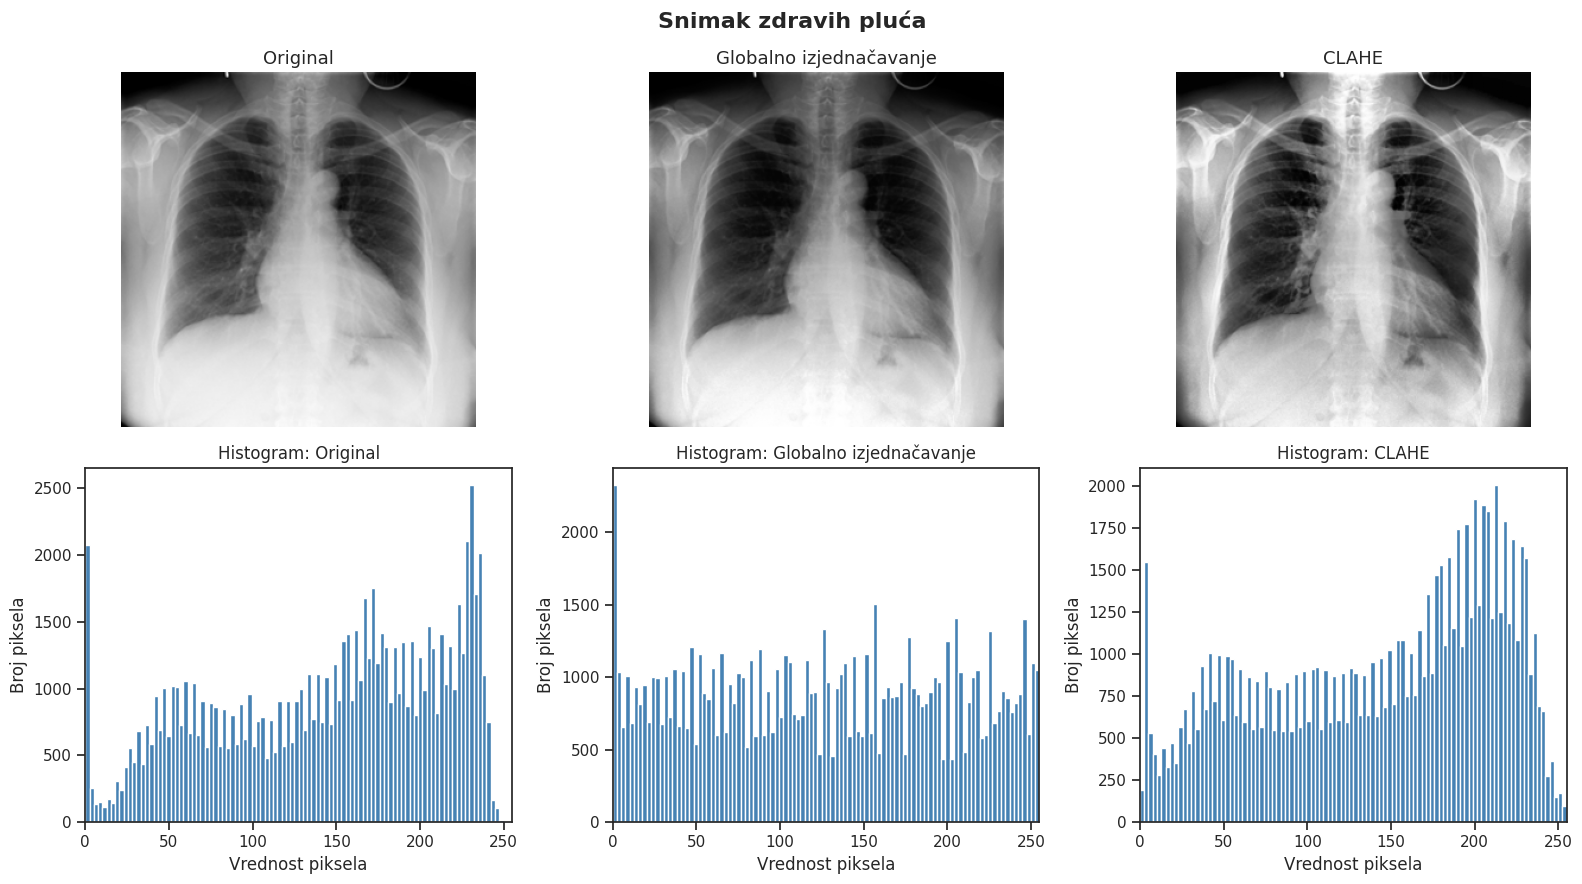

In [32]:
# Isto poređenje na snimku zdravih pluća: da li CLAHE i ovde daje bolji rezultat?
uporedi_kontrast('/content/COVID-19_Radiography_Dataset/Normal/images/Normal-16.png',
                 'Snimak zdravih pluća')

**Šta vidimo kod zdravih pluća?**

* **Original:** ovaj snimak već ima dobar kontrast; histogram je raširen skoro preko celog opsega (od oko 30 do 240).
* **Globalno izjednačavanje:** histogram postaje ravan, ali slika se **skoro ne menja**. Kada je kontrast već dobar, globalna metoda nema šta mnogo da popravi.
* **CLAHE:** jasno pojačava **lokalne detalje**: šara krvnih sudova u plućima je oštrija, kičma se vidi kroz senku srca, a ivice rebara i ključnih kostiju su izraženije. Pluća su tamna i „čista”, bez zamućenih površina.

**Poređenje sa COVID snimkom:** kod COVID snimka su globalno izjednačavanje i CLAHE dali veoma različite rezultate, jer je original bio slabog kontrasta. Kod ovog snimka globalno izjednačavanje gotovo ništa ne menja, a CLAHE i dalje ističe detalje. CLAHE, dakle, radi dobro i na lošim i na dobrim snimcima, pa daje **ujednačeniji** ulaz za model.

**Zaključak:** za predobradu biramo **CLAHE**, kao i autori DeTraC-a.

Zašto je za model važno da snimci iz različitih izvora posle predobrade izgledaju što sličnije?

Da bi model učio razlike koje potiču od bolesti, a ne od aparata i načina snimanja.

# **Predloženi korak 2: DeTraC model**

DeTraC je duboka **konvoluciona** mreža koja koristi transfer learning: znanje naučeno na velikom skupu opštih slika (ImageNet) prenosi na specifičan medicinski zadatak. Njena posebnost je **sloj dekompozicije klasa**, koji se dodaje pre, i **sloj kompozicije klasa**, koji se dodaje posle pretrenirane mreže.

DeTraC radi u tri faze:

**1. Dekompozicija klasa (razlaganje)**
* Pretrenirana mreža (kod autora **AlexNet**) izdvaja karakteristike iz svake slike: svaka slika postaje vektor brojeva.
* **PCA** (analiza glavnih komponenti) smanjuje dimenziju tih vektora i zadržava najvažnije pravce.
* **K-means** algoritam deli svaku klasu na **k podklasa** (autori koriste k = 2). Tri klase (normal, COVID-19, SARS) tako postaju **šest podklasa**, npr. COVID_1 i COVID_2.

**2. Transfer (prenos znanja)**
* Pretrenirana mreža se dotrenira da razlikuje **podklase**, a ne originalne klase. Svaka podklasa je „pravilnija” od cele klase, pa model lakše uči granice između njih.

**3. Kompozicija klasa (sastavljanje)**
* Za konačnu odluku podklase se ponovo spajaju: na primer, verovatnoća za COVID-19 je zbir verovatnoća za COVID_1 i COVID_2.



## **Praktični deo: pojednostavljeni DeTraC na našem dataset-u**

Implementiramo ideju DeTraC-a u varijanti koja se izvršava za nekoliko minuta:

1. **Podskup podataka:** 400 slika po klasi (samo `images`, bez maski), podeljeno 70% / 30% na obuku i test, **pre** bilo kakve obrade.
2. **Izdvajanje karakteristika:** pretrenirani MobileNetV2 (ImageNet) bez klasifikacione glave pretvara svaku sliku u vektor od 1280 brojeva. Autori su koristili AlexNet, koji ne postoji u Keras-u; ideja je ista.
3. **Dekompozicija:** PCA + k-means (k = 2) dele svaku klasu na 2 podklase → 8 podklasa.
4. **Transfer:** treniramo klasifikacionu glavu na 8 podklasa, i radi poređenja, običnu glavu na 4 klase.
5. **Kompozicija:** sabiramo verovatnoće podklasa iste klase → konačna odluka za 4 klase.

In [34]:
random.seed(42)
SRC = '/content/COVID-19_Radiography_Dataset'
DST = '/content/detrac_subset'
KLASE = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
N_PO_KLASI = 400     # 400 slika po klasi: dovoljno za demonstraciju, a brzo
TEST_UDEO = 0.3      # kao u radu: 70% obuka, 30% test

shutil.rmtree(DST, ignore_errors=True)
for k in KLASE:
    slike = sorted(glob(os.path.join(SRC, k, 'images', '*.png')))   # SAMO images, bez maski
    izbor = random.sample(slike, N_PO_KLASI)
    n_test = int(N_PO_KLASI * TEST_UDEO)
    for deo, lista in [('test', izbor[:n_test]), ('train', izbor[n_test:])]:
        os.makedirs(os.path.join(DST, deo, k), exist_ok=True)
        for p in lista:
            shutil.copy(p, os.path.join(DST, deo, k))
    print(f'{k:16s} obuka: {N_PO_KLASI - n_test}   test: {n_test}')

COVID            obuka: 280   test: 120
Lung_Opacity     obuka: 280   test: 120
Normal           obuka: 280   test: 120
Viral Pneumonia  obuka: 280   test: 120


**Izdvajanje karakteristika:** svaku sliku propuštamo kroz pretrenirani MobileNetV2 bez klasifikacione glave. Na izlazu dobijamo vektor od **1280 brojeva** koji opisuje sliku. Bazu ne treniramo (zamrznuta je), samo je koristimo.

Karakteristike računamo **jednom** i pamtimo ih. Kasnije treniramo samo malu glavu nad njima, što traje sekunde, a ne sate.

In [35]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG = 224
def ucitaj(deo):
    # shuffle=False čuva redosled, da znamo koja karakteristika pripada kojoj slici
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DST, deo), labels='inferred', label_mode='int', class_names=KLASE,
        image_size=(IMG, IMG), batch_size=32, shuffle=False)

train_ds = ucitaj('train')
test_ds = ucitaj('test')

# Pretrenirani MobileNetV2 bez glave; pooling='avg' daje vektor od 1280 karakteristika po slici
backbone = MobileNetV2(include_top=False, weights='imagenet', pooling='avg', input_shape=(IMG, IMG, 3))
backbone.trainable = False

def izvuci_karakteristike(ds):
    X, y = [], []
    for slike, labele in ds:
        X.append(backbone(preprocess_input(slike), training=False).numpy())
        y.append(labele.numpy())
    return np.concatenate(X), np.concatenate(y)

X_train, y_train = izvuci_karakteristike(train_ds)
X_test, y_test = izvuci_karakteristike(test_ds)
print('Obuka:', X_train.shape, '  Test:', X_test.shape)

Found 1120 files belonging to 4 classes.
Found 480 files belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Obuka: (1120, 1280)   Test: (480, 1280)


**Dekompozicija klasa:** PCA prvo svodi 1280 karakteristika na 50 najvažnijih pravaca. Zatim k-means **svaku klasu posebno** deli na 2 grupe najsličnijih slika. Svaka slika dobija novu labelu, npr. `COVID_1` ili `COVID_2`. Četiri klase tako postaju **osam podklasa**.

In [36]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

K = 2   # broj podklasa po klasi, kao u radu
pca = PCA(n_components=50, random_state=42).fit(X_train)
Z_train = pca.transform(X_train)

y_sub = np.zeros_like(y_train)          # nove labele: podklase
podklase = []
for c, ime in enumerate(KLASE):
    idx = np.where(y_train == c)[0]                      # slike klase c
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z_train[idx])
    y_sub[idx] = c * K + km.labels_                      # npr. COVID -> 0 ili 1, Lung_Opacity -> 2 ili 3...
    for j in range(K):
        podklase.append(f'{ime}_{j+1}')
        print(f'{ime + "_" + str(j+1):20s} {np.sum(km.labels_ == j):4d} slika')

COVID_1               162 slika
COVID_2               118 slika
Lung_Opacity_1        182 slika
Lung_Opacity_2         98 slika
Normal_1              232 slika
Normal_2               48 slika
Viral Pneumonia_1     154 slika
Viral Pneumonia_2     126 slika


**Rezultat dekompozicije:** k-means ne deli klase na jednake polovine. Kod COVID-a i virusne pneumonije podela je ujednačenija (162/118 i 154/126), dok je kod zdravih pluća izdvojena **mala, posebna grupa od 48 slika** (Normal_2). To je grupa koja se po karakteristikama jasno razlikuje od ostalih zdravih snimaka, setite se posebne „trake” zdravih snimaka na scatter grafiku u EDA.

**Šta je k-means podelio?** Gledamo po 5 slika iz svake podklase i pokušavamo da otkrijemo po čemu se razlikuju podklase iste klase.

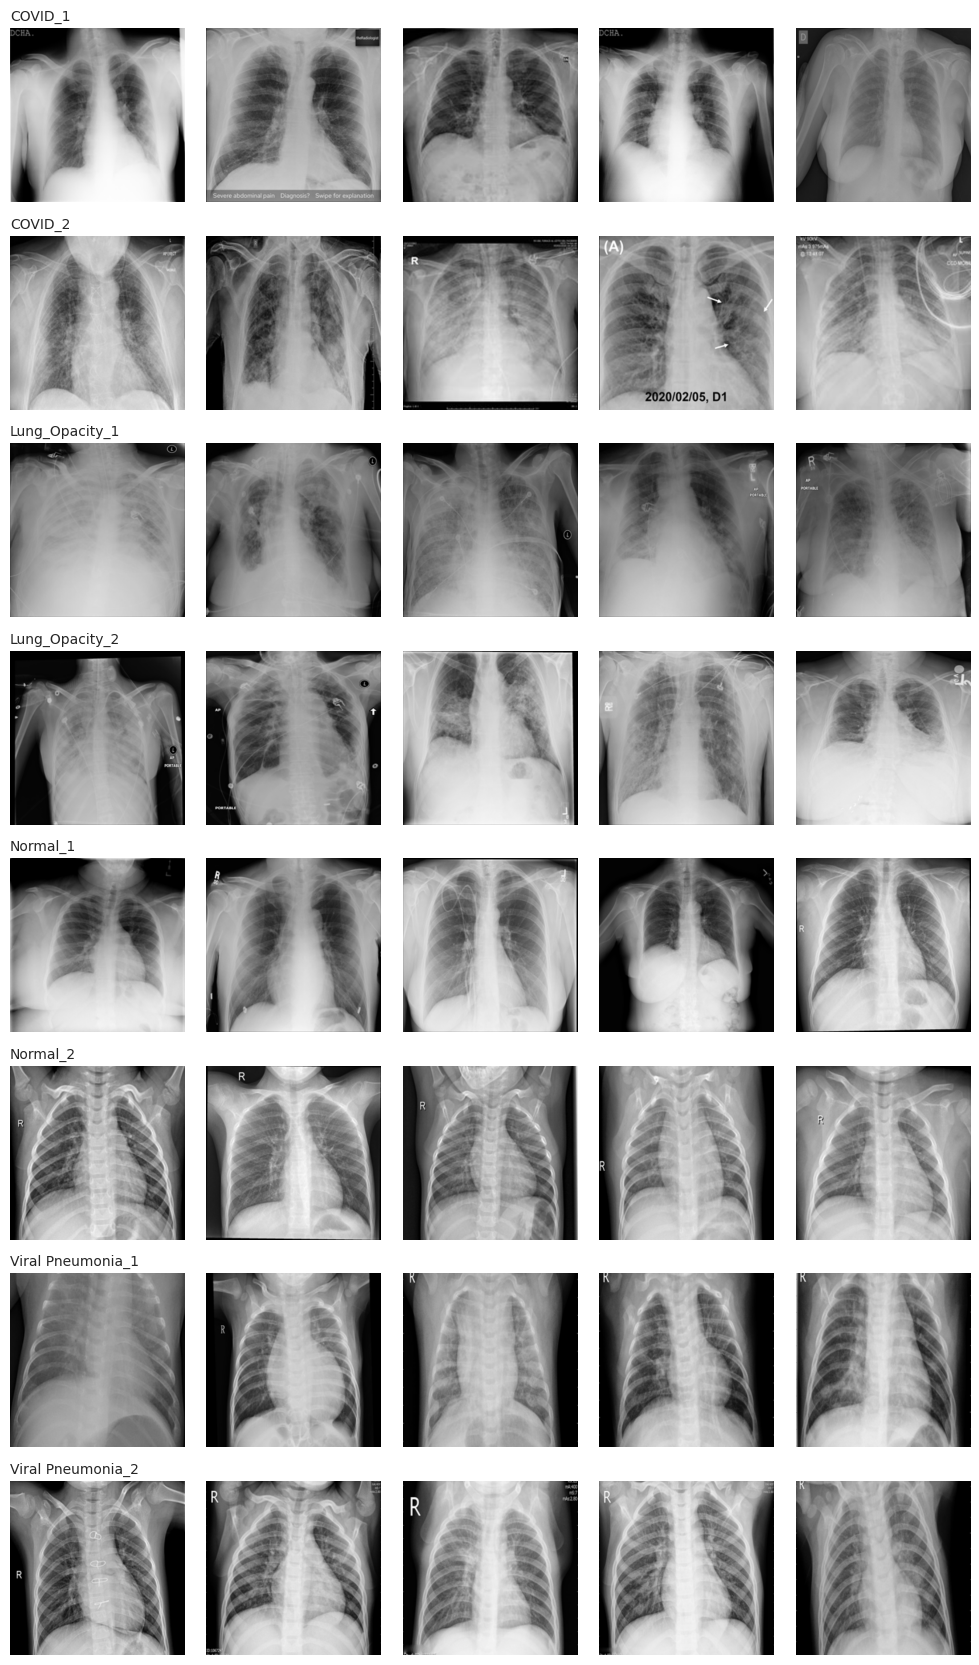

In [37]:
putanje_train = np.array(train_ds.file_paths)   # isti redosled kao X_train (shuffle=False)
fig, axs = plt.subplots(len(podklase), 5, figsize=(10, 2.1 * len(podklase)))
for s, ime in enumerate(podklase):
    idx = np.where(y_sub == s)[0][:5]
    for j in range(5):
        axs[s, j].axis('off')
        if j < len(idx):
            axs[s, j].imshow(cv2.imread(putanje_train[idx[j]]))
    axs[s, 0].set_title(ime, fontsize=10, loc='left')
plt.tight_layout()
plt.show()

**Šta je k-means pronašao?**

* **Normal_2 (48 slika) su dečji snimci:** mali grudni koš, uska rebra, oznaka „R”. Normal_1 su snimci odraslih. K-means je, bez ikakvog znanja o medicini, sam razdvojio decu od odraslih.
* **Viral Pneumonia (obe podklase) su takođe dečji snimci**, istog izgleda kao Normal_2. Snimci virusne pneumonije u ovom dataset-u potiču iz skupa dečjih snimaka.
* **COVID_2:** mnogo snimaka sa **natpisima i oznakama iz članaka**: slova „(A)”, strelice, datum („2020/02/05, D1”), tekst u uglovima. **COVID_1:** snimci sa logotipima i tekstom sa interneta (na jednom piše čak „Severe abdominal pain. Diagnosis? Swipe for explanation”, što je snimak sa društvenih mreža).
* **Lung_Opacity_1:** bledi, zamućeni snimci niskog kontrasta. **Lung_Opacity_2:** kontrastniji snimci sa crnim ivicama i natpisima „PORTABLE” (snimak u bolničkom krevetu).

**Zaključak:** podklase uglavnom ne odgovaraju stadijumima bolesti, nego **izvoru i načinu snimanja**: deca/odrasli, snimak iz članka/bolnice, kontrast i oznake.

**Šta to znači za model?** Model koji vidi dečji snimak može da zaključi „virusna pneumonija” samo zato što je pacijent dete. Model koji vidi strelice i datum na snimku može da zaključi „COVID” zbog natpisa, a ne zbog pluća. Ovo se zove **učenje prečica (shortcut learning)** i jedan je od glavnih razloga zašto modeli sa odličnim rezultatima u radovima ne rade dobro u bolnicama.

**Treniranje.** Nad izdvojenim karakteristikama treniramo dve iste male mreže:
* **osnovni model:** direktno 4 klase (ovo je *shallow tuning*: baza je zamrznuta, trenira se samo glava);
* **DeTraC glava:** 8 podklasa.

Iz obuke izdvajamo 20% za validaciju, stratifikovano po podklasama (svaka podklasa je zastupljena srazmerno). Svaki model dobija **nov** EarlyStopping callback; setite se iz prvog case study-ja da deljeni callback pamti stanje prethodnog treniranja.

In [38]:
from sklearn.model_selection import train_test_split

# Iz obuke izdvajamo 20% za validaciju; stratify=y_sub čuva udeo svake podklase u oba dela
idx_tr, idx_val = train_test_split(np.arange(len(y_train)), test_size=0.2,
                                   stratify=y_sub, random_state=42)

def napravi_glavu(n_izlaza):
    """Mala klasifikaciona glava koja radi nad 1280 karakteristika iz MobileNetV2."""
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),           # ulaz: vektor od 1280 brojeva
        tf.keras.layers.Dense(256, activation='relu'),              # skriveni sloj
        tf.keras.layers.Dropout(0.3),                               # isključuje 30% neurona, protiv overfitting-a
        tf.keras.layers.Dense(n_izlaza, activation='softmax')])     # izlaz: verovatnoća za svaku (pod)klasu
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',           # labele su celi brojevi (0, 1, 2...)
                  metrics=['accuracy'])
    return model

def treniraj(model, y):
    """Trenira model; svaki poziv pravi NOV EarlyStopping callback."""
    return model.fit(X_train[idx_tr], y[idx_tr],
                     validation_data=(X_train[idx_val], y[idx_val]),
                     epochs=50, batch_size=32, verbose=0,
                     callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                                                 restore_best_weights=True)])

tf.keras.utils.set_random_seed(42)                                  # ponovljivi rezultati

# Osnovni model: uči direktno 4 originalne klase
osnovni = napravi_glavu(len(KLASE))
h_osn = treniraj(osnovni, y_train)

# DeTraC glava: uči 8 podklasa dobijenih k-means-om
detrac = napravi_glavu(len(podklase))
h_det = treniraj(detrac, y_sub)

print('Osnovni model: epoha', len(h_osn.history['loss']), '| DeTraC glava: epoha', len(h_det.history['loss']))

Osnovni model: epoha 10 | DeTraC glava: epoha 17


Osnovni model je zaustavljen posle 10, a DeTraC glava posle 17 epoha (EarlyStopping, kada validacioni gubitak 5 epoha zaredom ne opada). DeTraC glava ima teži zadatak, 8 podklasa umesto 4 klase, pa uči duže.

**Kompozicija i evaluacija na test skupu.** DeTraC glava daje 8 verovatnoća za svaku sliku. Verovatnoće dve podklase iste klase sabiramo, npr. P(COVID) = P(COVID_1) + P(COVID_2), i biramo klasu sa najvećom verovatnoćom.

Tačnost bez dekompozicije: 0.860
Tačnost DeTraC:            0.856

Osnovni model:
                  precision    recall  f1-score   support

          COVID      0.777     0.900     0.834       120
   Lung_Opacity      0.872     0.792     0.830       120
         Normal      0.856     0.792     0.823       120
Viral Pneumonia      0.950     0.958     0.954       120

       accuracy                          0.860       480
      macro avg      0.864     0.860     0.860       480
   weighted avg      0.864     0.860     0.860       480

DeTraC:
                  precision    recall  f1-score   support

          COVID      0.814     0.875     0.843       120
   Lung_Opacity      0.815     0.842     0.828       120
         Normal      0.867     0.758     0.809       120
Viral Pneumonia      0.934     0.950     0.942       120

       accuracy                          0.856       480
      macro avg      0.857     0.856     0.856       480
   weighted avg      0.857     0.856     0.856  

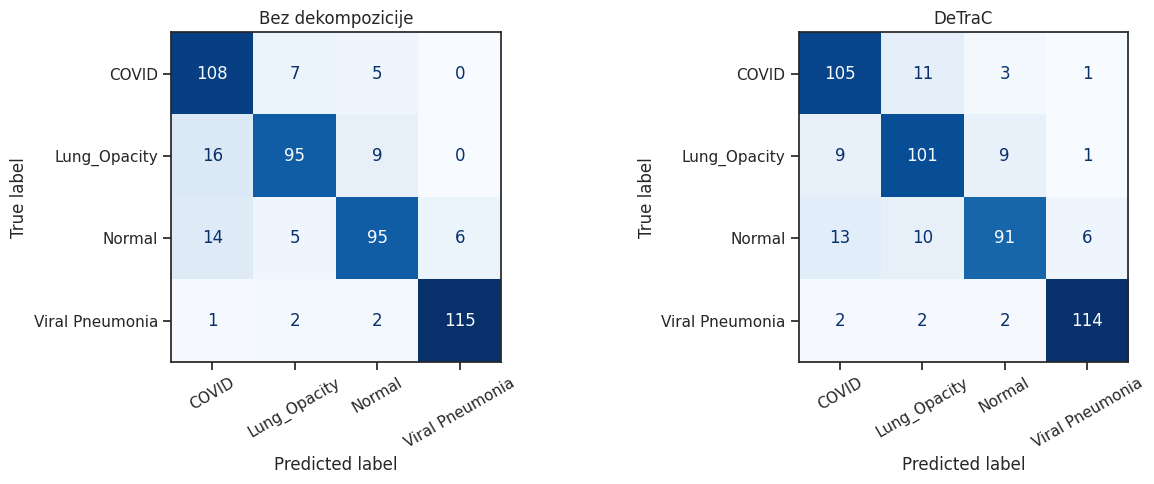

In [39]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Osnovni model: direktno 4 klase
pred_osn = osnovni.predict(X_test, verbose=0).argmax(axis=1)

# DeTraC: 8 verovatnoća -> KOMPOZICIJA -> 4 klase
p_sub = detrac.predict(X_test, verbose=0)                        # oblik (480, 8)
p_klasa = p_sub.reshape(len(p_sub), len(KLASE), K).sum(axis=2)   # (480, 4, 2) -> zbir podklasa -> (480, 4)
pred_det = p_klasa.argmax(axis=1)

print(f'Tačnost bez dekompozicije: {accuracy_score(y_test, pred_osn):.3f}')
print(f'Tačnost DeTraC:            {accuracy_score(y_test, pred_det):.3f}\n')
print('Osnovni model:\n', classification_report(y_test, pred_osn, target_names=KLASE, digits=3))
print('DeTraC:\n', classification_report(y_test, pred_det, target_names=KLASE, digits=3))

# Matrice konfuzije jedna pored druge
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, naslov in [(axs[0], pred_osn, 'Bez dekompozicije'), (axs[1], pred_det, 'DeTraC')]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=KLASE, ax=ax,
                                            cmap='Blues', colorbar=False, xticks_rotation=30)
    ax.set_title(naslov); ax.grid(False)
plt.tight_layout()
plt.show()

**Rezultati:**

| | Bez dekompozicije | DeTraC |
|---|---|---|
| Tačnost | **86.0%** (413/480) | 85.6% (411/480) |
| Odziv COVID | **0.900** | 0.875 |
| Odziv Lung Opacity | 0.792 | **0.842** |
| Odziv Normal | **0.792** | 0.758 |
| Odziv Viral Pneumonia | **0.958** | 0.950 |

**Tumačenje:**
* Oba modela imaju praktično **istu tačnost**: razlika je samo **2 slike od 480**, što je u granicama slučajnosti.
* DeTraC je bolje prepoznao **zamućenje pluća** (odziv 0.84 umesto 0.79), ali lošije **zdrava pluća** i **COVID**. Dekompozicija je pomerila greške, a nije ih smanjila.
* **Virusna pneumonija** se kod oba modela prepoznaje najbolje (oko 95%). Setite se šta smo videli kod podklasa: to su dečji snimci, pa model verovatno delom prepoznaje **dete**, a ne bolest.
* **COVID** ima odziv 0.88–0.90: od 120 COVID snimaka model propusti 12 do 15.

**Zašto DeTraC ovde ne pomaže kao u radu?**
1. Autori su imali samo **196 slika** iz različitih izvora, a mi 1600 izbalansiranih. Dekompozicija najviše pomaže kada je skup mali i klase jako nepravilne.
2. Trenirali smo samo glavu (*shallow tuning*); autori su najbolje rezultate dobili sa *deep tuning*-om cele mreže.
3. Njihov test skup je sadržao augmentovane kopije trening slika (curenje podataka), pa su njihovih 97% preterano optimistični.

#**Predložen korak 3: Transfer learning**


Tokom faze transfer learning u modelu DeTraC korišćene su različite konvolucione neuronske mreže prethodno obučene na ImageNet skupu podataka, uključujući AlexNet, VGG19, ResNet, GoogleNet i SqueezeNet.

Primenjeni parametri tokmo treniranja su dati u sledećoj tabeli:

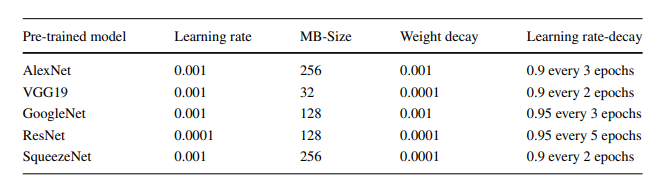

Za **sloj dekompozicije** autori su koristili pretreniranu mrežu **AlexNet** u režimu plitkog učenja (shallow tuning): mreža samo izdvaja karakteristike slika tri originalne klase, a ne trenira se.

AlexNet (2012) je jedna od prvih dubokih CNN mreža: ima **pet konvolucionih slojeva** (filteri 11×11, 5×5 i 3×3), max-pooling slojeve 3×3 i ReLU aktivacije, a zatim **tri potpuno povezana sloja** za klasifikaciju. Poslednji sloj je prilagođen broju klasa u radu.

U našem praktičnom delu smo umesto AlexNet-a koristili **MobileNetV2**, jer AlexNet ne postoji u Keras-u. Uloga je ista: izdvajanje karakteristika za k-means.

**Koliko su veliki pretrenirani modeli?** Autori su probali pet mreža; najbolji rezultat dao je VGG19. Poredimo broj parametara (samo konvolucioni deo, bez klasifikacione glave):

In [40]:
# Poređenje veličine pretreniranih modela (bez klasifikacione glave)
from tensorflow.keras.applications import VGG19, ResNet50, MobileNetV2

for ime, M in [('VGG19', VGG19), ('ResNet50', ResNet50), ('MobileNetV2', MobileNetV2)]:
    model = M(include_top=False, weights=None, input_shape=(224, 224, 3))
    print(f'{ime:12s} slojeva: {len(model.layers):4d}   parametara: {model.count_params():>12,}')

VGG19        slojeva:   22   parametara:   20,024,384
ResNet50     slojeva:  175   parametara:   23,587,712
MobileNetV2  slojeva:  154   parametara:    2,257,984


**Šta vidimo?**
* **VGG19** ima samo 22 sloja, ali 20 miliona parametara: slojevi su „široki” (mnogo filtera 3×3).
* **ResNet50** ima 175 slojeva i 23.6 miliona parametara: duboka mreža sa rezidualnim vezama.
* **MobileNetV2** ima 154 sloja, a samo 2.3 miliona parametara, **skoro 10 puta manje** od VGG19, zahvaljujući dubinskim (depthwise) konvolucijama.

Zato smo za praktični deo izabrali MobileNetV2: izdvajanje karakteristika je brzo i na običnom računaru, a kvalitet karakteristika je dovoljan za demonstraciju metode.

#**Predloženi korak 4: Treniranje i testiranje modela**

Skup podataka je zatim podeljen u dve grupe: 70% za obuku modela i
30% za procenu učinka klasifikacije.

Parametri treniranja dati su u tabeli iz koraka 3 (optimizator SGD sa momentumom, mali learning rate koji se postepeno smanjuje). Napomena: podela 70/30 urađena je **posle** augmentacije, pa test skup sadrži kopije trening slika. U našem praktičnom delu podelu smo uradili **pre** bilo kakve obrade.

Prikaz tačnosti (**Accuracy**) krive učenja i greška dobijene pomoću **DeTraC** modela kada se **VGG19** koristi kao prethodno obučen model:

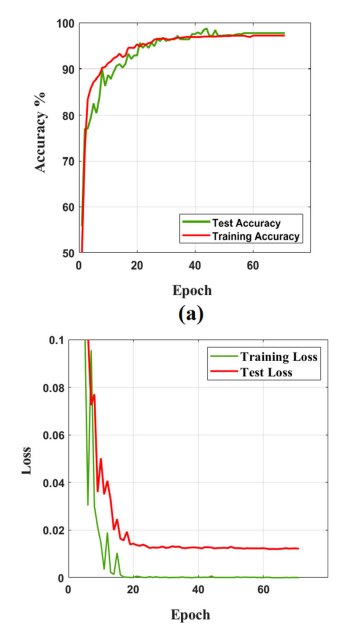

**Šta vidimo na graficima?**

* **Tačnost:** test tačnost raste zajedno sa trening tačnošću i posle oko 40. epohe je **jednaka ili čak veća** od trening tačnosti (oko 97–98%). To je neobično: model obično radi bolje na slikama koje je video. Jedno moguće objašnjenje je da test skup sadrži augmentovane kopije trening slika (curenje podataka), pa je test skup „lak”.
* **Gubitak:** trening gubitak pada skoro na nulu posle 20. epohe, a test gubitak ostaje oko 0.012. Vrednosti gubitka su vrlo male, što odgovara MSE gubitku (srednja kvadratna greška), koji su autori koristili.
* **Pažnja na boje:** na gornjem grafiku zelena je **test**, a na donjem zelena je **trening**. Uvek čitajte legendu.
* U legendi piše **Test Accuracy** i **Test Loss**: autori su tokom treniranja pratili test skup, a ne poseban validacioni skup. Kada test skup utiče na odluke tokom treniranja (npr. kada stati), on više nije potpuno „neviđen”, pa je konačni rezultat optimističan.

#**Predložen korak 5: Analiza rezultata**


Da bi demonstrirali robusnost modela **DeTraC**, autori rada su koristili različite CNN modele unapred obučene na ImageNet skupu podataka (kao što su **AlexNet, VGG19, ResNet, GoogleNet i SqueezeNet**) u fazi transfer učenja u okviru **DeTraC** arhitekture.

Radi fer poređenja, takođe su uporedili performanse različitih verzija DeTraC modela direktno sa pomenutim unapred obučenim modelima, i to u plitkom (**shallow**) i dubokom (**deep**) režimu fino podešavanja (**fine-tuning**).

Kada koristimo pretrained CNN (npr. model treniran na ImageNet datasetu), on već zna da prepoznaje osnovne oblike, ivice, teksture, šare itd.
Zato ga ne moramo trenirati od nule — dovoljno je prilagoditi (fino dotrenirati) model da prepozna tvoje konkretne klase (npr. COVID, Normal, Pneumonia). To prilagođavanje zovemo ***fine-tuning***.

Prikaz rezultata za različite CNN modele:

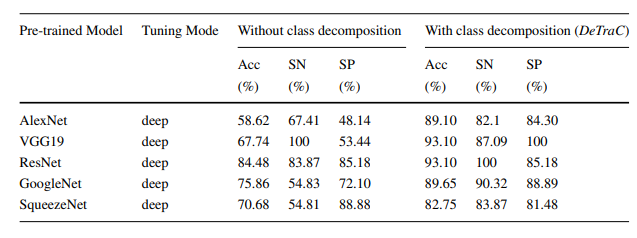


**Tumačenje tabele** (režim deep tuning; Acc = tačnost, SN = osetljivost, SP = specifičnost):

* **Sa dekompozicijom (DeTraC)** svi modeli rade znatno bolje nego bez nje. Najveći skok ima VGG19: sa **67.74%** na **93.10%** tačnosti. Najbolju tačnost, 93.10%, imaju DeTraC sa VGG19 i sa ResNet-om.
* **Bez dekompozicije** VGG19 ima osetljivost 100%, a specifičnost samo 53%: model skoro sve snimke proglašava bolesnim. Zato tačnost sama nije dovoljna; treba gledati i SN i SP.



**ROC kriva za DeTraC model treniran na pre-treniranom modelu VGG19.**

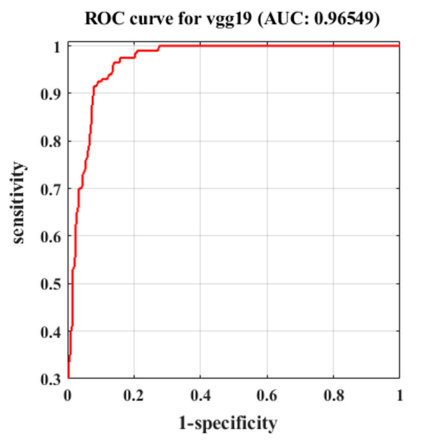

**Kako čitati ROC krivu?**

Model za svaku sliku daje verovatnoću bolesti. Da bismo dobili odluku „bolestan / zdrav”, biramo **prag**: npr. ako je verovatnoća veća od 0.5, snimak je bolestan. ROC kriva prikazuje šta se dešava za **sve moguće pragove**:
* **y osa: osetljivost** (sensitivity), odnosno koliki deo bolesnih model pronalazi;
* **x osa: 1 − specifičnost** (stopa lažno pozitivnih), odnosno koliki deo zdravih model pogrešno proglasi bolesnim.

Idealan model ide pravo gore do vrha, pa desno (gornji levi ugao). Model koji nasumično pogađa daje dijagonalu od (0, 0) do (1, 1).

**AUC** (Area Under the Curve) je površina ispod krive: 1 je savršen model, a 0.5 nasumično pogađanje. DeTraC sa VGG19 ima **AUC = 0.965**, što je vrlo dobro.

Primer čitanja: uz oko 8% lažno pozitivnih (x ≈ 0.08), model pronalazi oko 92% bolesnih (y ≈ 0.92).

 Primetite da **y osa počinje od 0.3**, a ne od 0. Tako kriva izgleda strmije, a model bolje nego što bi izgledao na grafiku sa punim opsegom osa.


#**Predloženi korak 6: Diskusija i zaključak**

Da bi demonstrirali robusnost i doprinos sloja dekompozicije klase modela
DeTraC-a tokom transformacije znanja korišćenjem
transfernog učenja, autori su koristili i različite prethodno obučene CNN
modele kao što su AlexNet, VGG, ResNet, GoogleNet i
SqueezeNet. Eksperimentalni rezultati su pokazali visoku tačnost u
obrađivanju podataka korišćenih u ovom radu sa
svim prethodno obučenim modelima, koji su koristili obuku u režimu *deep-tuning*, za razliku od *shallow-tuning*.

Sledeći podaci to pokazuju:


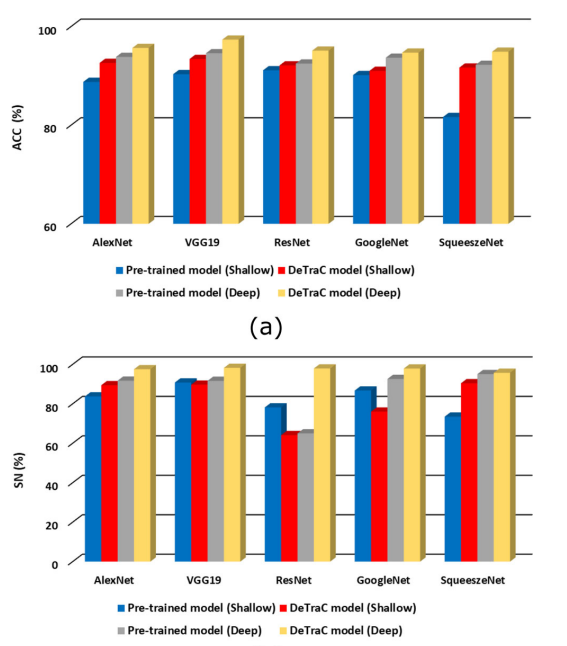



**Tumačenje grafika** (a: tačnost, b: osetljivost):

* **Žuti stubići (DeTraC, deep tuning)** su najviši kod svih pet mreža, i po tačnosti i po osetljivosti. Najbolji rezultat ima VGG19, oko 97%.
* **Deep tuning** (sivo, žuto) je skoro uvek bolji od **shallow tuning-a** (plavo, crveno).
* Postoje i izuzeci: kod ResNet-a i GoogleNet-a, DeTraC u shallow režimu (crveno) ima **nižu** osetljivost od običnog pretreniranog modela (plavo). Dekompozicija dakle ne pomaže uvek; najviše pomaže u kombinaciji sa deep tuning-om.


Ovde je tačnost modela između 80% i 97%, a u tabeli iz koraka 5 bez dekompozicije AlexNet ima samo 58.6%. Grafik i tabela su dobijeni na **različitim test skupovima**: ovaj grafik na testu sa augmentovanim slikama, a tabela i sledeći grafik na originalnim slikama. Zato ih ne možemo direktno porediti. Pouzdaniji su rezultati na originalnim slikama (najviše 93.1%).

**Zaključak autora:** DeTraC, odnosno sloj dekompozicije klasa uz pretreniranu mrežu u režimu deep tuning, daje značajno bolju tačnost od pretreniranih modela bez dekompozicije, kod svih pet mreža. Najveći skokovi su kod AlexNet-a (sa 58.6% na 89.1%) i VGG19 (sa 67.7% na 93.1%).

**Ali pogledajmo grafik (b), osetljivost:** kod VGG19 pretrenirani model **bez** dekompozicije ima osetljivost 100%, a DeTraC 87%. Tačnost je porasla, ali je DeTraC propustio više bolesnih. Rezultat zavisi od toga koju metriku gledamo.

**Naš eksperiment nasuprot radu:** u našem praktičnom delu dekompozicija nije poboljšala rezultat (86.0% bez nje, 85.6% sa njom). Razlog nije nužno to što metoda ne radi, nego različiti uslovi: mi smo imali veći i izbalansiran skup (1600 slika) i trenirali samo glavu, a autori mali, neujednačen skup (196 slika), deep tuning i test skup sa augmentovanim kopijama.


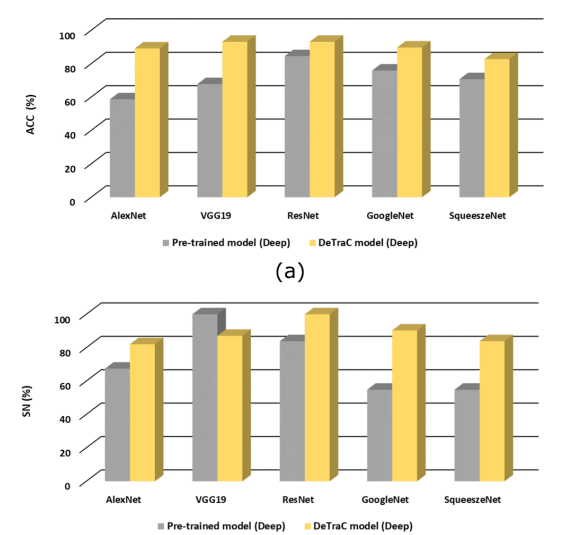


# **Kritički osvrt: koliko verujemo ovim rezultatima?**

Sva tri rada prijavljuju tačnost od 90% do 98%. Ipak, ovakvi modeli se tokom pandemije nisu masovno koristili u bolnicama. Nekoliko razloga smo videli i sami u ovoj svesci:

1. **Učenje prečica (shortcut learning).** Na COVID snimcima ima natpisa, strelica i datuma iz članaka i sa društvenih mreža; snimci virusne pneumonije su dečji. Model može da nauči natpise ili uzrast pacijenta umesto bolesti. (Videli smo kod podklasa k-means-a.)
2. **Različiti izvori za različite klase.** EDA je pokazala da se klase razlikuju po osvetljenosti, kontrastu i kadriranju. Model može da nauči da prepozna bolnicu ili aparat.
3. **Curenje podataka (data leakage).** Augmentacija pre podele na skupove (DeTraC) i praćenje test skupa tokom treniranja daju preterano optimistične rezultate.
4. **Neravnoteža klasa.** Tačnost sama nije dovoljna: potrebni su odziv (osetljivost), preciznost i specifičnost po klasama, posebno za COVID.
5. **Greške u radovima.** Videli smo F1 veći od preciznosti i osetljivosti (prvi rad) i osetljivost citiranu kao tačnost (DeTraC).
6. **Nema spoljašnje validacije.** Pravi test je bolnica čije snimke model nikada nije video.

**Zaključak case study-ja:** visoka tačnost u radu je tek prvi korak. Kao inženjeri uvek pitamo: kako su podaci podeljeni, na čemu je model testiran i **šta model zaista gleda** (npr. pomoću Grad-CAM mapa ili maski pluća iz dataset-a). Ista pitanja postavite i u svojim projektima.
